# ISAF project — Model 3: Tabular Foundation Model (TabPFN)

**Client (hypothetical):** a consumer lender. **Decision:** approve a personal loan if the predicted probability that it is paid back (`loan_paid_back = 1`, the *favourable* outcome) is above a threshold.

**Legal constraint: `gender` and `marital_status` are NOT model inputs.** Sex cannot be a credit criterion: EU Directive 2004/113/EC covers access to goods and services, including financial services, and the US ECOA covers both sex and marital status. As in the LR and XGBoost notebooks, the model uses the **9 other features**. The two attributes are used only to **audit** fairness, which is what the EU AI Act expects of a high-risk system.

This notebook evaluates **TabPFN** on the four dimensions of the brief (**performance** (statistical and economic), **interpretability**, **stability**, **fairness**) with the shared toolkit `src/isaf_eval.py`. The LR and XGBoost notebooks use the same splits and functions, so the numbers can be compared directly. It ends with a **robust TabPFN** built from the diagnostics (section 8).

| | |
|---|---|
| Data | Kaggle Playground S5E11: 594k loans, 11 features (9 used as model inputs), *synthetic* (generated from "Loan Prediction 2025") |
| Test set | 20,000 held-out rows (`make_splits`), **the same for the 3 models** |
| Threshold | chosen on a separate 5,000-row validation set, never on test |
| Runtime | first run: about 3 h on an M4 Pro GPU (keep the laptop awake) (MPS); every TabPFN result is cached in `outputs/cache/` (committed), so a rerun takes about 1 min |

**How the notebook maps to the course**

| Course chapter | Where |
|---|---|
| Global interpretability: PDP, global surrogate | 5.4, 5.5 |
| Local interpretability: LIME, ICE, SHAP | 5.2, 5.3, 5.4 |
| Explaining performance: permutation importance, XPER | 5.1, 5.6 |
| Disagreement problem (Krishna et al.) | 5.3, 5.7 |
| Stability (Turney; distance between models; randomness & reporting) | 6 |
| Fairness: tests, FPDP & candidate variables, mitigation, TOST equivalence | 7 |

In [1]:
import sys, json, time, platform, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.tree import DecisionTreeRegressor, plot_tree
warnings.filterwarnings("ignore")

ROOT = Path.cwd()
sys.path.append(str(ROOT / "src"))
from isaf_eval import *        # splits, metrics, fairness tests, XPER, LIME, SEED, TARGET, FEATURES, ...
from tabpfn_model import *     # TabPFNModel, BaggedTabPFN, encode, Cache, DEVICE, save_production_model

OUT = ROOT / "outputs"; FIG = OUT / "figures"; FIG.mkdir(parents=True, exist_ok=True)
cache = Cache(OUT / "cache", recompute=False)   # recompute=True -> rerun every TabPFN computation

N_CONTEXT = 10_000   # rows given to TabPFN as context (inference cost grows with it -> laptop compute budget)
N_ESTIMATORS = 4     # TabPFN internal ensemble size (8 = +0.001 AUC for 2x the time)
N_REFITS = 5         # stability refits
N_STAB = 2_000       # test rows used in the stability experiments
DELTA_TOST = 0.02    # fairness-equivalence tolerance on approval rates, fixed BEFORE looking at results
PROHIBITED = ["gender", "marital_status"]   # legally prohibited as inputs: used for fairness AUDIT only
MODEL_FEATURES = [c for c in FEATURES if c not in PROHIBITED]

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
C = {"main": "#2563eb", "neg": "#dc2626", "grey": "#9ca3af", "ok": "#16a34a"}
def savefig(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", dpi=150, bbox_inches="tight"); plt.show()

**Reproducibility report.** The course's reporting standard for model-generated outputs (slide 222) applies to a foundation model too: which model, which version, how it was run.

In [2]:
import tabpfn, torch, sklearn, shap
_probe = TabPFNModel(n_estimators=1).fit(pd.DataFrame(np.random.rand(50, len(FEATURES)), columns=FEATURES), np.arange(50) % 2)
repro = {"model": "TabPFN (Prior Labs), in-context learning, no training on our data",
         "checkpoint": _probe.clf.configs_[0].name if hasattr(_probe.clf, "configs_") else "auto",
         "tabpfn package": tabpfn.__version__, "torch": torch.__version__, "scikit-learn": sklearn.__version__,
         "shap": shap.__version__, "python": platform.python_version(), "machine": platform.platform(),
         "device": DEVICE, "model inputs": ", ".join(MODEL_FEATURES), "n_estimators": N_ESTIMATORS, "context rows": N_CONTEXT, "seed": SEED,
         "query date": time.strftime("%Y-%m-%d")}
del _probe
display(pd.Series(repro, name="value").to_frame())

,value
model,"TabPFN (Prior Labs), in-context learning, no t..."
checkpoint,TabPFN-v3.5
tabpfn package,9.0.0
torch,2.14.0
scikit-learn,1.9.1
shap,0.51.0
python,3.11.16
machine,macOS-15.3.1-arm64-arm-64bit
device,mps
model inputs,"annual_income, debt_to_income_ratio, credit_sc..."


## 1. Data & shared split

In [3]:
df = load_data(ROOT)
fit_pool, test = make_splits(df)              # test = common 20k evaluation set (all 3 models)
train_pool, valid = make_validation(fit_pool) # valid = 5k rows to choose the threshold
context = stratified_subsample(train_pool, N_CONTEXT, SEED)   # TabPFN "training" set

levels = category_levels(df)
X_ctx, X_val, X_test = (encode(d, levels)[MODEL_FEATURES] for d in (context, valid, test))
y_ctx, y_val, y_test = (d[TARGET].to_numpy() for d in (context, valid, test))

display(pd.DataFrame({"rows": [len(df), len(train_pool), len(context), len(valid), len(test)],
                      "paid-back rate": [d[TARGET].mean() for d in (df, train_pool, context, valid, test)]},
                     index=["full data", "train pool", "TabPFN context", "validation", "test"]).round(3))

,rows,paid-back rate
full data,593994,0.799
train pool,470195,0.799
TabPFN context,10000,0.799
validation,5000,0.799
test,20000,0.799


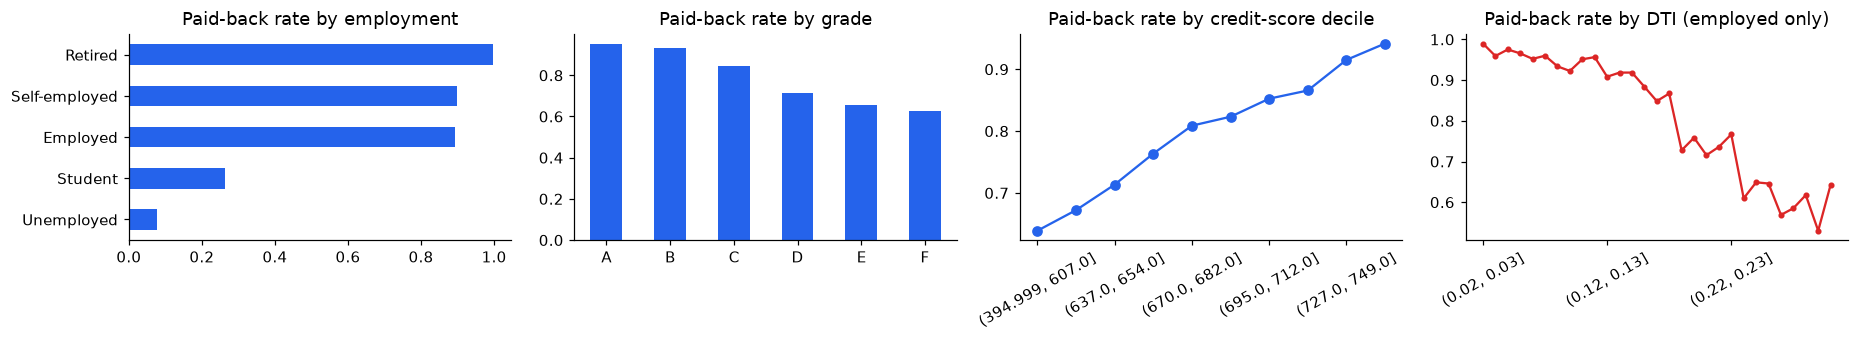

gender,Female,Male,Other
n,306175.000,284091.000,3728.000
paid_back_rate,0.802,0.796,0.795


marital_status,Divorced,Married,Single,Widowed
n,21312.000,277239.000,288843.000,6600.00
paid_back_rate,0.797,0.799,0.799,0.79


education_level,Bachelor's,High School,Master's,Other,PhD
n,279606.000,183592.00,93097.000,26677.000,11022.00
paid_back_rate,0.789,0.81,0.802,0.803,0.83


employment_status,Employed,Retired,Self-employed,Student,Unemployed
n,450645.000,16453.000,52480.000,11931.000,62485.000
paid_back_rate,0.894,0.997,0.898,0.264,0.078


In [4]:
# What drives repayment in the raw data? (useful to sanity-check the model later)
fig, ax = plt.subplots(1, 4, figsize=(17, 3.2))
df.groupby("employment_status")[TARGET].mean().sort_values().plot.barh(ax=ax[0], color=C["main"], title="Paid-back rate by employment")
df.groupby(df.grade_subgrade.str[0])[TARGET].mean().plot.bar(ax=ax[1], color=C["main"], rot=0, title="Paid-back rate by grade")
df.groupby(pd.qcut(df.credit_score, 10))[TARGET].mean().plot(ax=ax[2], marker="o", color=C["main"], rot=30, title="Paid-back rate by credit-score decile")
emp = df[df.employment_status == "Employed"]
emp.groupby(pd.cut(emp.debt_to_income_ratio, np.arange(0.02, 0.32, 0.01)), observed=True)[TARGET].mean().plot(
    ax=ax[3], marker=".", color=C["neg"], rot=30, title="Paid-back rate by DTI (employed only)")
for a in ax: a.set_xlabel(""); a.set_ylabel("")
savefig("01_data_drivers")

for col in SENSITIVE:
    display(df.groupby(col)[TARGET].agg(n="count", paid_back_rate="mean").round(3).T)

**Reading:**
- `employment_status` dominates. Unemployed borrowers repay about 8% of the time and students about 26%, against about 90% for employed borrowers. Grade and credit score are strongly monotone.
- The protected attributes (`gender`, `marital_status`) have almost identical base rates, so any large approval gap on them would have to come from the model and not from the data.
- ⚠️ **The DTI relationship is not smooth.** The repayment rate jumps in steps (for example 86.7% → 72.8% between DTI 0.17–0.18 and 0.18–0.19), and DTI only takes 526 distinct values. This is an artifact of the synthetic generator, and it explains the input-sensitivity results in section 6.2.

## 2. TabPFN

TabPFN is a transformer pre-trained on millions of synthetic tabular tasks. It does **in-context learning**: our 10k training rows are passed as context, and no gradient step is run on our data. Consequences:
- "fit" only stores the context and is instant. **Inference is the expensive part**, since each prediction attends over the 10k context rows;
- inference cost grows with the context size, so on a laptop GPU we use **10k context rows**, while LR/XGB can use the full 470k-row train pool;
- there are no coefficients or trees to read, so interpretability has to be **model-agnostic**.

In [5]:
model = TabPFNModel(features=MODEL_FEATURES, n_estimators=N_ESTIMATORS).fit(X_ctx, y_ctx)

t0 = time.time(); model.predict_proba(X_test.iloc[:200]); latency_ms = (time.time() - t0) / 200 * 1000
print(f"inference: {latency_ms:.1f} ms per applicant on {DEVICE}, amortised over a batch of 200 (a single applicant costs far more: see section 9)")

p_val  = cache("p_valid", lambda: model.predict_proba(X_val))
p_test = cache("p_test",  lambda: model.predict_proba(X_test))

inference: 55.2 ms per applicant on mps, amortised over a batch of 200 (a single applicant costs far more: see section 9)


## 3. Predictive performance: statistical

The 95% confidence intervals come from a bootstrap of the 20k test rows (500 resamples). A gap between two models smaller than this is not meaningful.

,AUC,Gini,PR-AUC,KS,Brier,LogLoss,ECE
TabPFN,0.9149,0.8298,0.9726,0.6661,0.0742,0.2534,0.0049


AUC 95% CI: [0.9102, 0.9202]   Brier 95% CI: [0.0716, 0.0767]   ECE (expected calibration error) = 0.0049


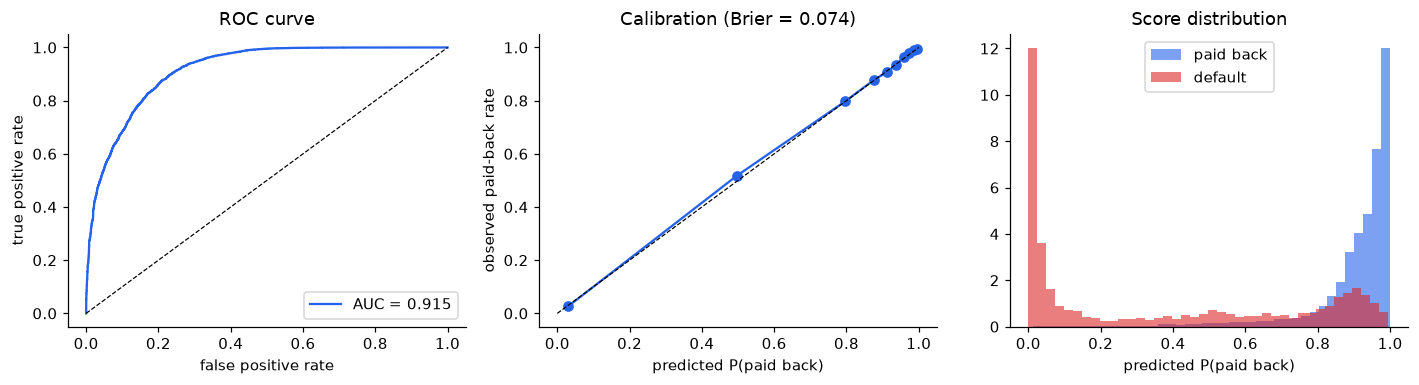

In [6]:
stats = statistical_metrics(y_test, p_test)
n = len(y_test)
ci = {"AUC": bootstrap_ci(lambda i: roc_auc_score(y_test[i], p_test[i]), n),
      "Brier": bootstrap_ci(lambda i: np.mean((p_test[i] - y_test[i]) ** 2), n)}
bins = pd.qcut(p_test, 10, labels=False, duplicates="drop")
stats["ECE"] = float(np.sum([np.mean(bins == b) * abs(p_test[bins == b].mean() - y_test[bins == b].mean()) for b in np.unique(bins)]))
display(pd.Series(stats, name="TabPFN").to_frame().T.round(4))
print(f"AUC 95% CI: [{ci['AUC'][0]:.4f}, {ci['AUC'][1]:.4f}]   Brier 95% CI: [{ci['Brier'][0]:.4f}, {ci['Brier'][1]:.4f}]   "
      f"ECE (expected calibration error) = {stats['ECE']:.4f}")

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
fpr, tpr, _ = roc_curve(y_test, p_test)
ax[0].plot(fpr, tpr, color=C["main"], label=f"AUC = {stats['AUC']:.3f}"); ax[0].plot([0, 1], [0, 1], "k--", lw=.8)
ax[0].set(xlabel="false positive rate", ylabel="true positive rate", title="ROC curve"); ax[0].legend()
fp, mp = calibration_curve(y_test, p_test, n_bins=10, strategy="quantile")
ax[1].plot(mp, fp, "o-", color=C["main"]); ax[1].plot([0, 1], [0, 1], "k--", lw=.8)
ax[1].set(xlabel="predicted P(paid back)", ylabel="observed paid-back rate", title=f"Calibration (Brier = {stats['Brier']:.3f})")
ax[2].hist(p_test[y_test == 1], bins=40, alpha=.6, color=C["main"], label="paid back", density=True)
ax[2].hist(p_test[y_test == 0], bins=40, alpha=.6, color=C["neg"], label="default", density=True)
ax[2].set(xlabel="predicted P(paid back)", title="Score distribution"); ax[2].legend()
savefig("02_statistical_performance")

## 4. Predictive performance: economic

Per-loan payoff for the lender:
- approve & paid back → **gain** = `loan_amount × interest_rate` (1-year horizon)
- approve & default → **loss** = `loan_amount × LGD` (LGD = 70%)
- reject → 0

The **threshold is chosen on the validation set** to maximise profit, then applied to the test set. Two benchmarks:
- **approve everyone**;
- the **status quo**: a grade-based rule (approve grades A to X), which is what a lender without a model would do.

We also report the loan-specific **expected-value rule** (approve iff `p·gain > (1−p)·loss`). It needs no tuning, but it only works if the probabilities are *calibrated*.

threshold chosen on validation: 0.80  |  status-quo rule: approve grades A–B
profit = 16.02 M€, 95% CI [15.30, 16.80] M€


,threshold,profit,profit_expected_value_rule,profit_approve_all,profit_oracle,share_of_oracle_captured,approval_rate,default_rate_among_approved,good_payers_rejected,profit_grade_rule_status_quo
TabPFN,0.8,1.602445e+07,1.646645e+07,-1.291119e+07,2.927522e+07,0.686,0.754,0.06,0.112,2086989.118


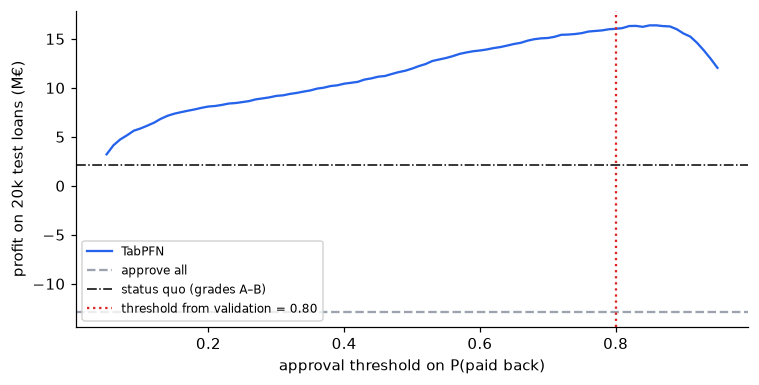

In [7]:
THRESH = best_threshold(y_val, p_val, valid.loan_amount, valid.interest_rate)
econ = economic_metrics(y_test, p_test, test.loan_amount, test.interest_rate, THRESH)

# Status-quo benchmark: approve all grades up to letter k (best k chosen on validation)
def grade_rule(d, k): return (d.grade_subgrade.str[0] <= "ABCDEF"[k]).astype(float).to_numpy()
best_k = max(range(6), key=lambda k: loan_profit(y_val, grade_rule(valid, k), valid.loan_amount, valid.interest_rate, 0.5))
profit_grade = loan_profit(y_test, grade_rule(test, best_k), test.loan_amount, test.interest_rate, 0.5)

la, ir = test.loan_amount.to_numpy(), test.interest_rate.to_numpy()
ci["profit"] = bootstrap_ci(lambda i: loan_profit(y_test[i], p_test[i], la[i], ir[i], THRESH), n)
print(f"threshold chosen on validation: {THRESH:.2f}  |  status-quo rule: approve grades A–{'ABCDEF'[best_k]}")
print(f"profit = {econ['profit']/1e6:.2f} M€, 95% CI [{ci['profit'][0]/1e6:.2f}, {ci['profit'][1]/1e6:.2f}] M€")
display(pd.Series({**econ, "profit_grade_rule_status_quo": profit_grade}, name="TabPFN").to_frame().T.round(3))

curve = profit_curve(y_test, p_test, test.loan_amount, test.interest_rate)
plt.figure(figsize=(7, 3.6))
plt.plot(curve.threshold, curve.profit / 1e6, color=C["main"], label="TabPFN")
plt.axhline(econ["profit_approve_all"] / 1e6, ls="--", c=C["grey"], label="approve all")
plt.axhline(profit_grade / 1e6, ls="-.", c="k", lw=1, label=f"status quo (grades A–{'ABCDEF'[best_k]})")
plt.axvline(THRESH, ls=":", c=C["neg"], label=f"threshold from validation = {THRESH:.2f}")
plt.xlabel("approval threshold on P(paid back)"); plt.ylabel("profit on 20k test loans (M€)"); plt.legend(fontsize=8)
savefig("03_profit_curve")

In [8]:
# Sensitivity to the LGD assumption (threshold re-chosen on validation for each LGD)
rows = []
for lgd in [0.4, 0.55, 0.7, 0.85, 1.0]:
    t = best_threshold(y_val, p_val, valid.loan_amount, valid.interest_rate, lgd=lgd)
    e = economic_metrics(y_test, p_test, test.loan_amount, test.interest_rate, t, lgd=lgd)
    rows.append({"LGD": lgd, "threshold": t, "profit (M€)": e["profit"] / 1e6,
                 "approval rate": e["approval_rate"], "share of oracle": e["share_of_oracle_captured"]})
display(pd.DataFrame(rows).set_index("LGD").round(3))

,threshold,profit (M€),approval rate,share of oracle
LGD,,,,
0.40,0.77,20.340,0.772,0.629
0.55,0.79,18.142,0.761,0.664
0.70,0.80,16.024,0.754,0.686
0.85,0.89,14.840,0.619,0.718
1.00,0.89,13.692,0.619,0.741


## 5. Interpretability (model-agnostic)

TabPFN has no internal structure we can read, so every tool here is **post-hoc and model-agnostic**. The course warns that such explanations can be unfaithful, unstable and contradictory (slide 42), so we measure each of these properties instead of assuming them:
- **5.1 Permutation importance:** which features the AUC depends on;
- **5.2 SHAP:** global drivers;
- **5.3 Local explanations:** SHAP and LIME on two applicants, plus their disagreement. This is the "right to an explanation" under GDPR art. 22 and the EU AI Act;
- **5.4 PDP and ICE:** the shape of the effects, and their heterogeneity;
- **5.5 Global surrogate:** a readable tree that mimics TabPFN, with its measured fidelity;
- **5.6 XPER:** where the AUC and the profit come from;
- **5.7 Disagreement between global methods.**

### 5.1 Permutation importance

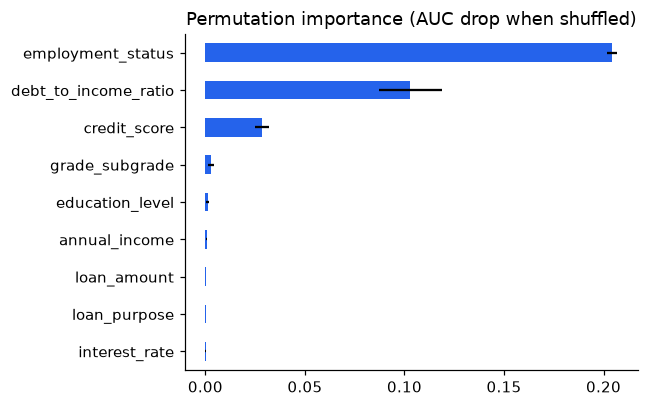

In [9]:
N_PI = 1_000
imp, imp_all = cache("perm_importance", lambda: permutation_importance_auc(model.predict_proba, X_test.iloc[:N_PI], y_test[:N_PI], n_repeats=2))
imp_sd = imp_all.groupby(level=0).std().reindex(imp.index)
imp.sort_values().plot.barh(figsize=(6, 3.8), color=C["main"], xerr=imp_sd.reindex(imp.sort_values().index),
                            title="Permutation importance (AUC drop when shuffled)")
savefig("04_permutation_importance")

### 5.2 SHAP (global)

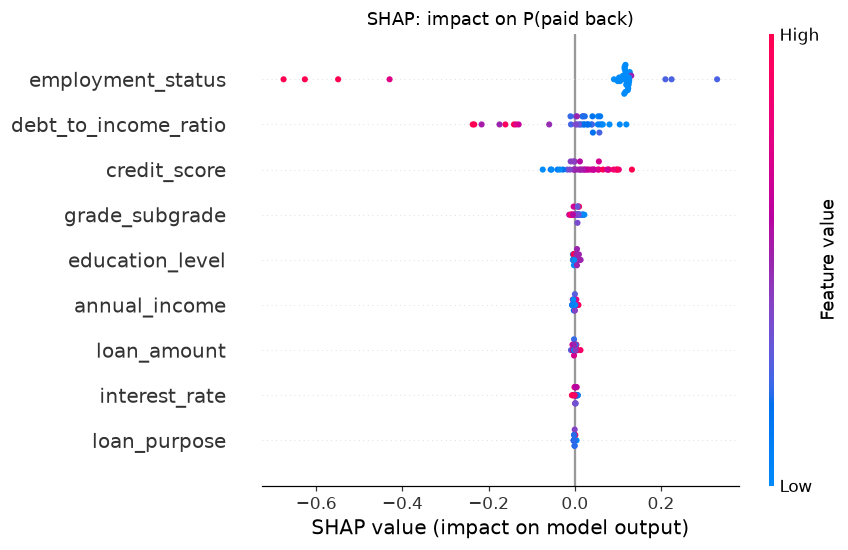

colour of categorical features = alphabetical code, e.g. employment_status: {0: 'Employed', 1: 'Retired', 2: 'Self-employed', 3: 'Student', 4: 'Unemployed'}


In [10]:
import shap

def explain(X_rows, n_background=20, max_evals=2 * len(MODEL_FEATURES) + 1, seed=SEED):
    # SHAP values of P(paid back); cost = rows x max_evals x n_background TabPFN predictions
    bg = X_val.sample(n_background, random_state=seed).to_numpy()
    f = lambda A: model.predict_proba(pd.DataFrame(A, columns=MODEL_FEATURES))
    ex = shap.PermutationExplainer(f, bg, feature_names=MODEL_FEATURES, seed=seed)
    sv = ex(X_rows.to_numpy(), max_evals=max_evals)
    return sv.values, sv.base_values

# Global SHAP on 40 test applicants
vals, base = cache("shap_global", lambda: explain(X_test.iloc[:40]))
sv = shap.Explanation(vals, base, data=X_test.iloc[:40].to_numpy(), feature_names=MODEL_FEATURES)
shap.plots.beeswarm(sv, max_display=9, show=False); plt.title("SHAP: impact on P(paid back)")
savefig("05_shap_global")
shap_imp = pd.Series(np.abs(vals).mean(axis=0), index=MODEL_FEATURES)
print("colour of categorical features = alphabetical code, e.g. employment_status:", dict(enumerate(levels["employment_status"])))

### 5.3 Local explanations: SHAP vs LIME, one rejected and one approved applicant

We pick two applicants just below and just above the threshold, the cases where a client asks "why?". Each one is explained twice:
- **SHAP** (Shapley values, permutation explainer);
- **LIME**: a sparse weighted linear model fitted on 2,000 perturbations around the applicant, with K = 5 features. We report its local fidelity R².

If the two methods rank the features differently, the explanation sent to the client depends on the method. This is the **disagreement problem** of Krishna et al.

REJECTED applicant #4266: main reasons lowering the score (SHAP) -> debt_to_income_ratio=0.235 (-0.112), credit_score=642 (-0.039), grade_subgrade=D2 (-0.004)
APPROVED applicant #17921: main reasons lowering the score (SHAP) -> debt_to_income_ratio=0.31 (-0.152), loan_purpose=Other (+0.001), loan_amount=9093.0 (+0.001)


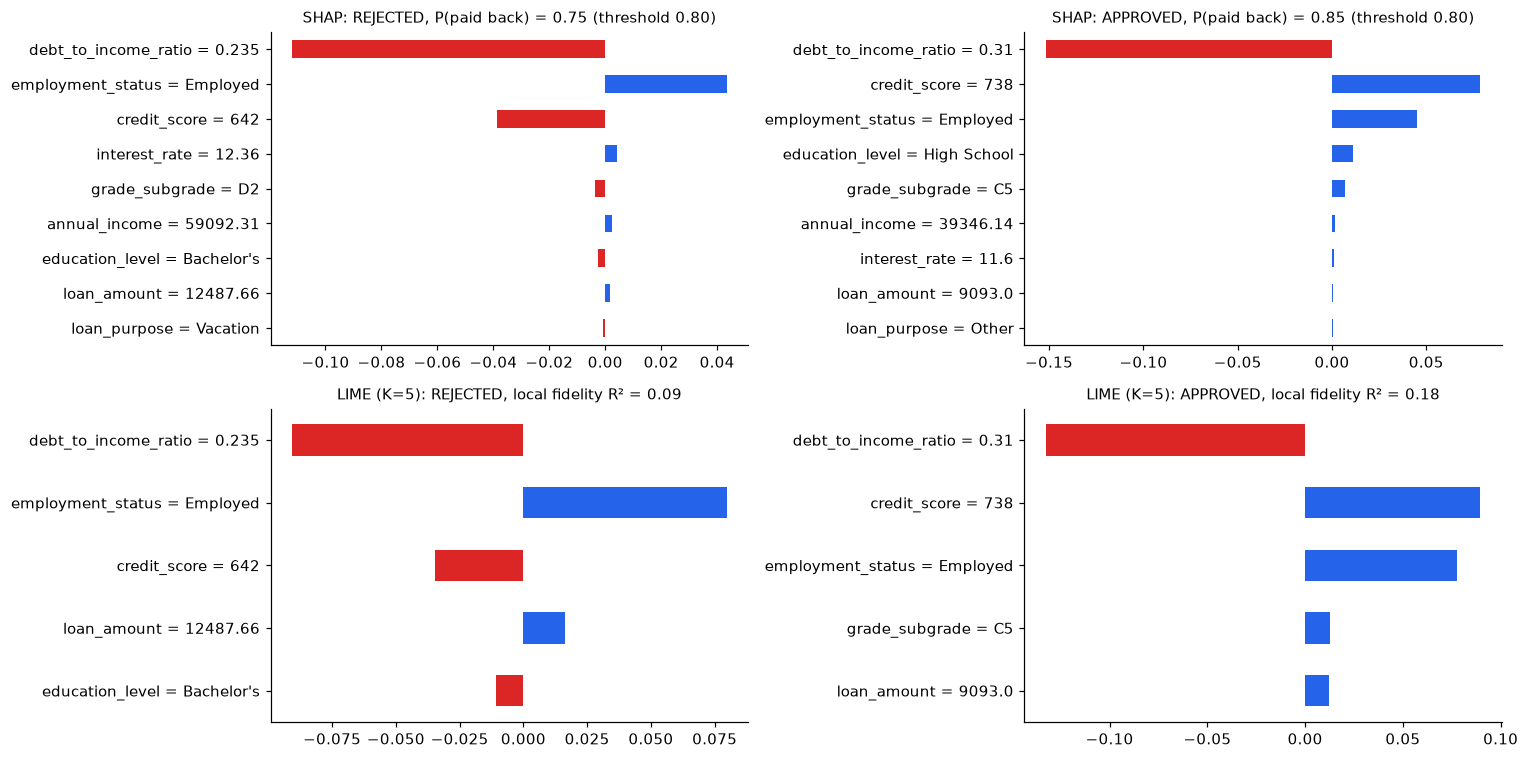

,spearman,top-3 agreement
SHAP vs LIME,,
REJECTED,0.63,1.0
APPROVED,0.77,1.0


In [11]:
rej = int(np.argmin(np.where(p_test < THRESH, np.abs(p_test - (THRESH - 0.05)), np.inf)))
acc = int(np.argmin(np.where(p_test >= THRESH, np.abs(p_test - (THRESH + 0.05)), np.inf)))
vals_loc, base_loc = cache("shap_local", lambda: explain(X_test.iloc[[rej, acc]], n_background=50, max_evals=100))
limes = cache("lime_local", lambda: [lime_explain(model.predict_proba, X_test.iloc[[i]], X_val, n_samples=2000, K=5)
                                     for i in (rej, acc)])

fig, ax = plt.subplots(2, 2, figsize=(14, 7))
agree = {}
for k, (i, label) in enumerate([(rej, "REJECTED"), (acc, "APPROVED")]):
    shap_i = pd.Series(vals_loc[k], index=MODEL_FEATURES)
    contrib = shap_i.rename(lambda c: f"{c} = {test.loc[i, c]}")
    contrib = contrib.reindex(contrib.abs().sort_values().index)
    contrib.plot.barh(ax=ax[0, k], color=np.where(contrib > 0, C["main"], C["neg"]))
    ax[0, k].set_title(f"SHAP: {label}, P(paid back) = {p_test[i]:.2f} (threshold {THRESH:.2f})", fontsize=10)
    lw, lr2 = limes[k]
    lw.rename(lambda c: f"{c} = {test.loc[i, c]}").iloc[::-1].plot.barh(ax=ax[1, k], color=np.where(lw.iloc[::-1] > 0, C["main"], C["neg"]))
    ax[1, k].set_title(f"LIME (K=5): {label}, local fidelity R² = {lr2:.2f}", fontsize=10)
    agree[label] = rank_agreement(shap_i, lw.reindex(MODEL_FEATURES).fillna(0), k=3)
    top_neg = shap_i.nsmallest(3)
    print(f"{label} applicant #{i}: main reasons lowering the score (SHAP) ->",
          ", ".join(f"{c}={test.loc[i, c]} ({v:+.3f})" for c, v in top_neg.items()))
savefig("06_local_explanations_shap_lime")
display(pd.DataFrame(agree).T.round(2).rename_axis("SHAP vs LIME"))

**Reading:** SHAP and LIME **agree on the ranking**: for the rejected applicant, both name the DTI (0.235) as the main reason. But LIME's **local fidelity is low** (R² of 0.09 and 0.18): a sparse linear model does not reproduce TabPFN around these applicants, because the model is driven by interactions (employment × DTI × credit score). This is the course's warning about post-hoc explainers (slide 42), measured here and not just assumed: the explanation looks convincing, but the surrogate behind it is a poor approximation of the model.

### 5.4 Partial dependence (PDP) and individual conditional expectation (ICE)

The PDP is the average effect of a feature. The ICE curves show the effect for each applicant: if the curves are not parallel, the average hides heterogeneous effects (slides 121–127). PDPs assume the features are independent, so values far from the data (e.g. a DTI of 0.5 combined with a high income) should be read with care.

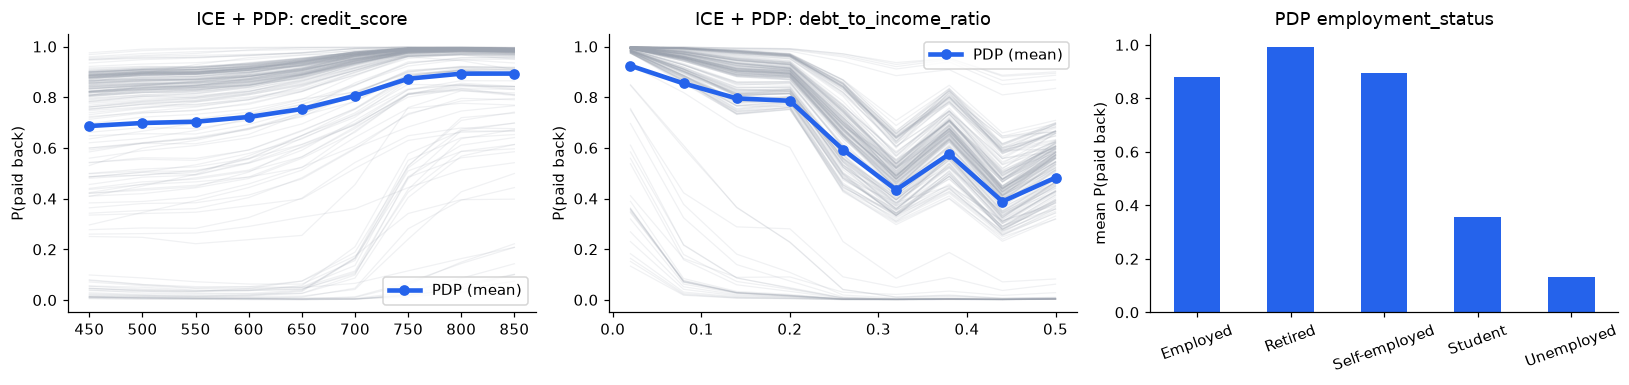

In [12]:
def ice(feature, grid, n=200):
    base = X_test.iloc[:n]
    Xs = pd.concat([base.assign(**{feature: v}) for v in grid], ignore_index=True)
    return pd.DataFrame(model.predict_proba(Xs).reshape(len(grid), n), index=grid)

ices = cache("ice", lambda: {"credit_score": ice("credit_score", np.linspace(450, 850, 9)),
                             "debt_to_income_ratio": ice("debt_to_income_ratio", np.linspace(0.02, 0.5, 9))})
def pdp(feature, grid, n=300):
    base = X_test.iloc[:n]
    Xs_ = pd.concat([base.assign(**{feature: v}) for v in grid], ignore_index=True)
    return pd.Series(model.predict_proba(Xs_).reshape(len(grid), n).mean(axis=1), index=grid)
pdps = cache("pdp", lambda: {"employment_status": pdp("employment_status", range(len(levels["employment_status"])))})

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for a, f in zip(ax, ["credit_score", "debt_to_income_ratio"]):
    a.plot(ices[f].index, ices[f].to_numpy(), color=C["grey"], alpha=.15, lw=.8)
    a.plot(ices[f].index, ices[f].mean(axis=1), color=C["main"], lw=3, marker="o", label="PDP (mean)")
    a.set(title=f"ICE + PDP: {f}", ylabel="P(paid back)"); a.legend()
pdps["employment_status"].rename(dict(enumerate(levels["employment_status"]))).plot.bar(ax=ax[2], color=C["main"], rot=20, title="PDP employment_status")
ax[2].set_ylabel("mean P(paid back)")
savefig("07_pdp_ice")

### 5.5 Global surrogate

We train a depth-3 decision tree to mimic TabPFN's predictions on 10k test applicants, and measure its **fidelity** (R² between the tree and TabPFN) on the other 10k. A high fidelity gives a readable summary of the black box. The course's warning still applies (slide 87): the tree explains TabPFN only up to 1 − R², and it can give an **illusion of interpretability**.

surrogate fidelity R² = 0.919 | AUC of the surrogate itself = 0.882 (TabPFN: 0.915)


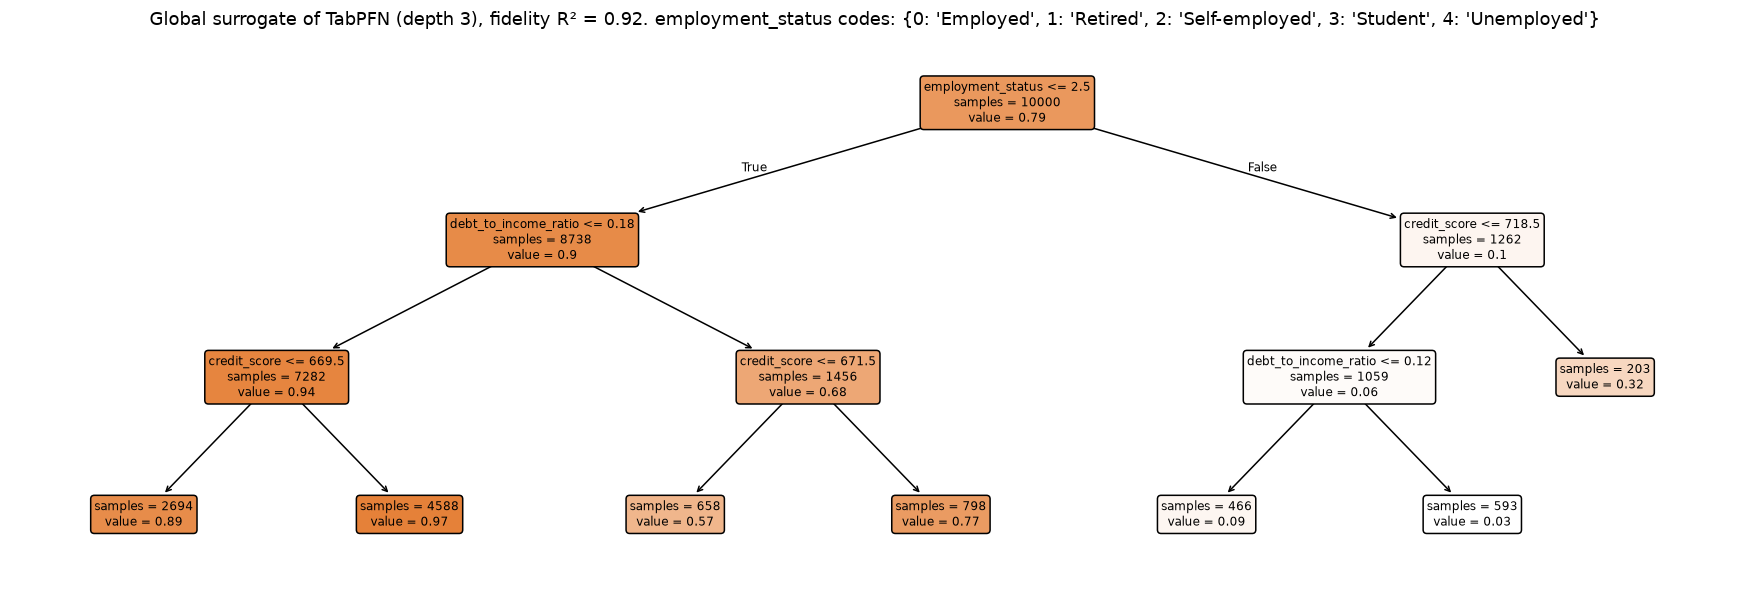

In [13]:
half = len(X_test) // 2
sur = DecisionTreeRegressor(max_depth=3, min_samples_leaf=200, random_state=SEED).fit(X_test.iloc[:half], p_test[:half])
fidelity = sur.score(X_test.iloc[half:], p_test[half:])
fid_auc = roc_auc_score(y_test[half:], sur.predict(X_test.iloc[half:]))
print(f"surrogate fidelity R² = {fidelity:.3f} | AUC of the surrogate itself = {fid_auc:.3f} (TabPFN: {stats['AUC']:.3f})")
plt.figure(figsize=(16, 5.5))
plot_tree(sur, feature_names=MODEL_FEATURES, filled=True, rounded=True, impurity=False, precision=2, fontsize=8)
plt.title(f"Global surrogate of TabPFN (depth 3), fidelity R² = {fidelity:.2f}. employment_status codes: {dict(enumerate(levels['employment_status']))}")
savefig("08_global_surrogate")

### 5.6 XPER: where do the AUC and the profit come from?

SHAP explains *predictions*. **XPER** (Hué, Hurlin, Pérignon & Saurin) explains *performance*: it is a Shapley decomposition of a performance metric, `PM = φ0 + Σ φj`. We decompose both the **AUC** and the **profit at the production threshold** on 1,000 test applicants, over 6 groups of the 9 input features (2⁶ = 64 coalitions, computed exactly):
- a feature group outside the coalition is replaced by the values of a random other applicant;
- φ0 is the performance with no information: AUC = 0.5, and the profit of a model that knows nothing.

This is the "language management understands" (slide 169): how many euros each piece of information earns.

,AUC,profit (k€)
phi_0 (no information),0.483,-446.000
employment,0.232,793.266
debt-to-income,0.143,465.725
credit score,0.049,80.863
grade & rate,0.008,16.547
income & amount,0.001,-4.184
education & purpose,0.003,-1.710
= full model,0.919,904.508


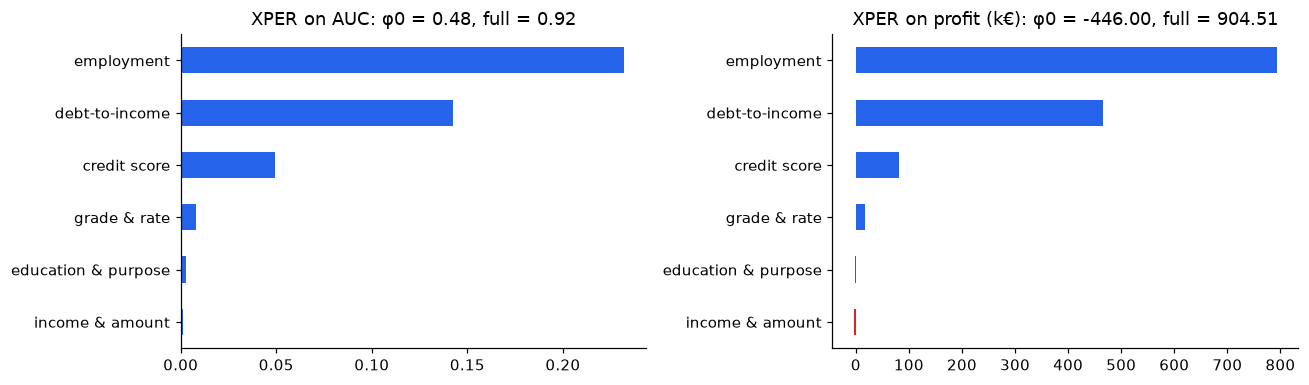

In [14]:
GROUPS = {"employment": ["employment_status"], "debt-to-income": ["debt_to_income_ratio"],
          "credit score": ["credit_score"], "grade & rate": ["grade_subgrade", "interest_rate"],
          "income & amount": ["annual_income", "loan_amount"],
          "education & purpose": ["education_level", "loan_purpose"]}
N_X = 1_000
yx, lax, irx = y_test[:N_X], la[:N_X], ir[:N_X]
xp = cache("xper", lambda: xper(model.predict_proba, X_test.iloc[:N_X],
                                {"AUC": lambda p: roc_auc_score(yx, p),
                                 "profit (k€)": lambda p: loan_profit(yx, p, lax, irx, THRESH) / 1e3},
                                GROUPS))
display(xp.round(3))
fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
for a, m in zip(ax, xp.columns):
    s = xp[m].drop(["phi_0 (no information)", "= full model"]).sort_values()
    s.plot.barh(ax=a, color=np.where(s > 0, C["main"], C["neg"]))
    a.set_title(f"XPER on {m}: φ0 = {xp[m].iloc[0]:.2f}, full = {xp[m].iloc[-1]:.2f}")
savefig("09_xper")

### 5.7 Do the global methods agree?
The same question as 5.3, for the global ranking of drivers: permutation importance, mean |SHAP| and the surrogate's importances (feature level), then also XPER (group level).

In [15]:
sur_imp = pd.Series(sur.feature_importances_, index=MODEL_FEATURES)
feat_methods = pd.DataFrame({"permutation importance": imp, "mean |SHAP|": shap_imp, "surrogate tree": sur_imp})
display(feat_methods.rank(ascending=False).astype(int).sort_values("permutation importance"))
pairs = [("permutation importance", "mean |SHAP|"), ("permutation importance", "surrogate tree"), ("mean |SHAP|", "surrogate tree")]
display(pd.DataFrame({f"{a} vs {b}": rank_agreement(feat_methods[a], feat_methods[b]) for a, b in pairs}).T.round(2))

to_group = lambda s: pd.Series({g: s[cols].sum() for g, cols in GROUPS.items()})
grp = pd.DataFrame({"XPER (AUC)": xp["AUC"].reindex(GROUPS.keys()), "XPER (profit)": xp["profit (k€)"].reindex(GROUPS.keys()),
                    "permutation importance": to_group(imp), "mean |SHAP|": to_group(shap_imp)})
print("group level: shares of the total")
display((grp / grp.sum()).round(3))

,permutation importance,mean |SHAP|,surrogate tree
employment_status,1,1,1
debt_to_income_ratio,2,2,2
credit_score,3,3,3
grade_subgrade,4,4,6
education_level,5,5,6
annual_income,6,6,6
loan_amount,7,7,6
loan_purpose,8,9,6
interest_rate,9,8,6


,spearman,top-3 agreement
permutation importance vs mean |SHAP|,0.98,1.0
permutation importance vs surrogate tree,0.84,1.0
mean |SHAP| vs surrogate tree,0.84,1.0


group level: shares of the total


,XPER (AUC),XPER (profit),permutation importance,mean |SHAP|
employment,0.532,0.587,0.600,0.574
debt-to-income,0.327,0.345,0.302,0.218
credit score,0.113,0.060,0.084,0.137
grade & rate,0.019,0.012,0.009,0.035
income & amount,0.003,-0.003,0.002,0.018
education & purpose,0.006,-0.001,0.003,0.019


## 6. Stability

**Definition (Turney 1995, slide 182):** two samples drawn from the same population should give approximately the same model. The data has no time dimension, so there is no temporal drift to test. Each test below is scored on the same 2,000 test applicants:
1. **Context resampling**: 5 different 10k context sets. This is TabPFN's own version of Turney's question, and the risk specific to TabPFN, since LR/XGB are trained on the whole pool;
2. **Seed only**: same context, 5 random seeds. This isolates the model's internal randomness;
3. **Context size**: AUC with 1k, 2.5k, 5k and 10k context rows;
4. **Input perturbation**: 1% and 5% Gaussian noise on numeric inputs (measurement error or small manipulation).

We also measure the **stability of the explanations**: the **distance between models** `‖φ(f1) − φ(f2)‖` of their permutation importances (slide 193) and the Spearman correlation of the rankings. "Material flips" are decision flips for applicants whose score is more than 0.05 from the threshold, i.e. clear-cut cases.

In [16]:
Xs, ys = X_test.iloc[:N_STAB], y_test[:N_STAB]

def refit_predict(ctx_df, seed, with_importance=False):
    m = TabPFNModel(features=MODEL_FEATURES, n_estimators=N_ESTIMATORS, seed=seed).fit(encode(ctx_df, levels), ctx_df[TARGET])
    out = {"p": m.predict_proba(Xs)}
    if with_importance:
        out["imp"] = permutation_importance_auc(m.predict_proba, Xs.iloc[:300], ys[:300], n_repeats=1)[0].to_numpy()
    del m; free_mem()
    return out

resample = [cache(f"stab_context_{s}", lambda s=s: refit_predict(stratified_subsample(train_pool, N_CONTEXT, 100 + s), 100 + s, True))
            for s in range(N_REFITS)]
seeds = [cache(f"stab_seed_{s}", lambda s=s: refit_predict(context, 100 + s)) for s in range(N_REFITS)]
sizes = {n_: cache(f"stab_size_{n_}", lambda n_=n_: refit_predict(stratified_subsample(train_pool, n_, SEED), SEED)) for n_ in [1_000, 2_500, 5_000]}
sizes[N_CONTEXT] = {"p": p_test[:N_STAB]}
noisy = {nz: cache(f"stab_noise_{nz}", lambda nz=nz: model.predict_proba(add_noise(Xs, NUM_COLS, nz))) for nz in [0.01, 0.05]}

def material_flips(P, t=THRESH, band=0.05):
    P = np.asarray(P); clear = np.abs(P[0] - t) > band
    return float(np.mean([np.mean((P[0][clear] >= t) != (q[clear] >= t)) for q in P[1:]]))

P_res, P_seed = np.array([r["p"] for r in resample]), np.array([r["p"] for r in seeds])
aucs_of = lambda P: [roc_auc_score(ys, p) for p in P]
stab = pd.DataFrame({
    "context resampling": {**prediction_stability(P_res, THRESH), "material flips": material_flips(P_res), "AUC mean": np.mean(aucs_of(P_res)), "AUC std": np.std(aucs_of(P_res))},
    "seed only":          {**prediction_stability(P_seed, THRESH), "material flips": material_flips(P_seed), "AUC mean": np.mean(aucs_of(P_seed)), "AUC std": np.std(aucs_of(P_seed))},
    **{f"noise {int(nz*100)}%": {**prediction_stability(np.array([p_test[:N_STAB], p]), THRESH), "material flips": material_flips([p_test[:N_STAB], p])} for nz, p in noisy.items()},
}).T
IMP = np.array([r["imp"] for r in resample])
IMP_SPEARMAN = importance_stability(IMP)
dist = [np.linalg.norm(IMP[i] - IMP[j]) for i in range(len(IMP)) for j in range(i + 1, len(IMP))]
IMP_DIST, IMP_DIST_REL = float(np.mean(dist)), float(np.mean(dist) / np.mean(np.linalg.norm(IMP, axis=1)))
display(stab.round(4))
print(f"explanations across context resamples: mean Spearman of importance rankings = {IMP_SPEARMAN:.3f}; "
      f"distance ‖φ(f1) − φ(f2)‖ = {IMP_DIST:.4f} ({IMP_DIST_REL:.0%} of the norm of φ)")

,mean_abs_prob_change,decision_flip_rate,mean_per_row_std,material flips,AUC mean,AUC std
context resampling,0.0246,0.0376,0.0185,0.0195,0.9196,0.0014
seed only,0.0055,0.0088,0.0041,0.0000,0.9209,0.0003
noise 1%,0.0206,0.0385,0.0103,0.0173,NaN,NaN
noise 5%,0.0257,0.0505,0.0129,0.0281,NaN,NaN


explanations across context resamples: mean Spearman of importance rankings = 0.791; distance ‖φ(f1) − φ(f2)‖ = 0.0160 (8% of the norm of φ)


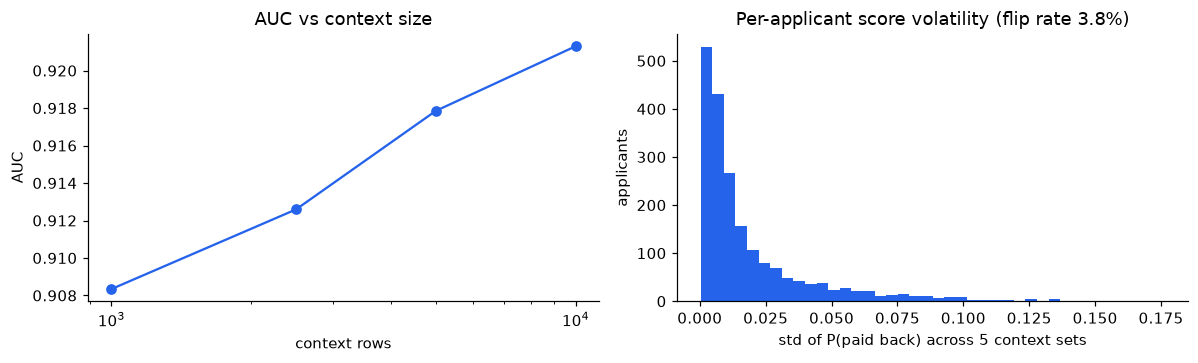

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
ns = sorted(sizes); aucs = [roc_auc_score(ys, sizes[k]["p"]) for k in ns]
ax[0].plot(ns, aucs, "o-", color=C["main"]); ax[0].set(xscale="log", xlabel="context rows", ylabel="AUC", title="AUC vs context size")
ax[1].hist(P_res.std(axis=0), bins=40, color=C["main"])
ax[1].set(xlabel="std of P(paid back) across 5 context sets", ylabel="applicants",
          title=f"Per-applicant score volatility (flip rate {stab.loc['context resampling', 'decision_flip_rate']:.1%})")
savefig("10_stability")

### 6.2 Where does the sensitivity to input noise come from?
1% noise flips about 4% of decisions. Is it TabPFN, a single feature, or the data? We run three checks:
- **one feature at a time:** 1% noise on each numeric feature separately;
- **the "fingerprint" feature:** by default, TabPFN appends a **hash of each row** as an extra feature, meant to distinguish duplicate rows. A hash changes completely when any input changes by one cent. We add €0.01 to the income, with and without the fingerprint;
- **reference models:** a logistic regression and a gradient-boosting model (sklearn `HistGradientBoosting`, standing in for XGBoost) trained on the whole train pool, under the same noise.

**Reading:** almost all the sensitivity comes from `debt_to_income_ratio`, the feature whose relationship with repayment is stepped in the synthetic data (section 1). Both flexible models follow the steps: TabPFN (3.6% with noise on DTI alone) more than the GBM (1.1%), and far more than the smooth logistic regression (0.1%). The fingerprint hash adds a small pure-noise effect (0.1% of decisions change for one cent), which disappears when it is switched off, at no cost in AUC.

In [18]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import HistGradientBoostingClassifier

def flips_vs(p0, p1): return {"mean |Δp|": float(np.mean(np.abs(p0 - p1))), "flip rate": float(np.mean((p0 >= THRESH) != (p1 >= THRESH)))}
X_tr = encode(train_pool, levels)[MODEL_FEATURES]; y_tr = train_pool[TARGET]
CAT_IN = [c for c in CAT_COLS if c in MODEL_FEATURES]
refs = {"LR": make_pipeline(ColumnTransformer([("c", OneHotEncoder(handle_unknown="ignore"), CAT_IN), ("n", StandardScaler(), NUM_COLS)]),
                            LogisticRegression(max_iter=2000)).fit(X_tr, y_tr),
        "GBM": HistGradientBoostingClassifier(max_iter=300, categorical_features=[MODEL_FEATURES.index(c) for c in CAT_IN], random_state=SEED).fit(X_tr, y_tr)}
ref_pred = {k: (lambda X, m=m: m.predict_proba(X)[:, 1]) for k, m in refs.items()}

scen = {"1% noise, all numeric": add_noise(Xs, NUM_COLS, 0.01), **{f"1% noise, {c} only": add_noise(Xs, [c], 0.01) for c in NUM_COLS}}
tab_noise = cache("noise_by_feature", lambda: {k: model.predict_proba(v) for k, v in scen.items() if k != "1% noise, all numeric"})
tab_noise["1% noise, all numeric"] = noisy[0.01]
rows = {}
for k, Xn in scen.items():
    rows[k] = {"TabPFN flips": flips_vs(p_test[:N_STAB], tab_noise[k])["flip rate"],
               **{f"{r} flips": flips_vs(f(Xs), f(Xn))["flip rate"] for r, f in ref_pred.items()}}
display(pd.DataFrame(rows).T.round(4))

def fingerprint_test():
    X_cent = Xs.assign(annual_income=Xs.annual_income + 0.01)
    out = {"with fingerprint (default)": flips_vs(p_test[:N_STAB], model.predict_proba(X_cent))}
    m = TabPFNModel(features=MODEL_FEATURES, n_estimators=N_ESTIMATORS, fingerprint=False).fit(X_ctx, y_ctx)
    p0 = m.predict_proba(Xs)
    out["fingerprint off"] = {**flips_vs(p0, m.predict_proba(X_cent)), "AUC": roc_auc_score(ys, p0)}
    out["with fingerprint (default)"]["AUC"] = roc_auc_score(ys, p_test[:N_STAB])
    del m; free_mem()
    return out
print("Adding €0.01 to the annual income of 2,000 applicants:")
display(pd.DataFrame(cache("fingerprint_test", fingerprint_test)).T.round(4))

,TabPFN flips,LR flips,GBM flips
"1% noise, all numeric",0.0385,0.0015,0.0145
"1% noise, annual_income only",0.0020,0.0000,0.0020
"1% noise, debt_to_income_ratio only",0.0360,0.0010,0.0110
"1% noise, credit_score only",0.0005,0.0000,0.0015
"1% noise, loan_amount only",0.0025,0.0000,0.0015
"1% noise, interest_rate only",0.0000,0.0000,0.0000


Adding €0.01 to the annual income of 2,000 applicants:


,mean |Δp|,flip rate,AUC
with fingerprint (default),0.0009,0.001,0.9213
fingerprint off,0.0000,0.000,0.9209


**Floating-point reproducibility (slides 210–215).** Is the same model, on the same data, identical on the GPU (MPS) and on the CPU? Kernels on different hardware add up numbers in a different order.

In [19]:
def cpu_vs_gpu(n_rows=300):
    m = TabPFNModel(features=MODEL_FEATURES, n_estimators=N_ESTIMATORS, device="cpu").fit(X_ctx, y_ctx)
    p_cpu = m.predict_proba(X_test.iloc[:n_rows]); del m
    return p_cpu
p_cpu = cache("cpu_vs_gpu", cpu_vs_gpu)
d = np.abs(p_cpu - p_test[:len(p_cpu)])
print(f"CPU vs MPS on {len(p_cpu)} applicants: max |Δp| = {d.max():.2e}, mean |Δp| = {d.mean():.2e}, "
      f"decision flips = {np.sum((p_cpu >= THRESH) != (p_test[:len(p_cpu)] >= THRESH))}; same run twice on MPS: identical (checked)")

CPU vs MPS on 300 applicants: max |Δp| = 5.03e-03, mean |Δp| = 2.32e-04, decision flips = 0; same run twice on MPS: identical (checked)


## 7. Fairness

Sensitive attributes:
- `gender` and `marital_status` are **protected** (EU anti-discrimination law, ECOA in the US);
- `education_level` and `employment_status` are not protected as such, but they are classic proxies for social origin and age. Employment is also a *legitimate* risk factor, and deciding that is a business and legal call.

We follow the course's **3-step approach** (Hurlin, Pérignon & Saurin, slide 235):
1. **test** fairness formally;
2. **find** the variables that drive unfairness (FPDP, candidate variables);
3. **mitigate** at the lowest performance cost.

A formal test can reject fairness but never prove it. For that, we add the **equivalence test (TOST)**. Convention as in the course: Y = 1 is favourable (paid back), "approved" = P(paid back) ≥ threshold.

### 7.1 Descriptive view

,DP difference,DP ratio,passes 4/5 rule,EO difference,min group AUC,max group AUC
attribute,,,,,,
gender,0.070,0.915,True,0.044,0.911,0.936
marital_status,0.028,0.963,True,0.103,0.863,0.917
education_level,0.074,0.910,True,0.090,0.882,0.924
employment_status,0.999,0.001,False,1.000,0.809,0.978


Headline Female vs Male (the 'Other' group has only 118 rows): approval gap = +0.004, TPR gap = -0.004


,n,base_rate,mean_score,approval_rate,TPR,FPR,AUC
gender,,,,,,,
Female,10155,0.801,0.799,0.756,0.886,0.231,0.911
Male,9727,0.795,0.793,0.752,0.890,0.217,0.918
Other,118,0.847,0.839,0.822,0.930,0.222,0.936


,n,base_rate,mean_score,approval_rate,TPR,FPR,AUC
marital_status,,,,,,,
Divorced,762,0.802,0.797,0.739,0.845,0.311,0.863
Married,9294,0.797,0.798,0.755,0.889,0.230,0.916
Single,9757,0.801,0.795,0.755,0.890,0.212,0.917
Widowed,187,0.743,0.769,0.727,0.906,0.208,0.916


,n,base_rate,mean_score,approval_rate,TPR,FPR,AUC
education_level,,,,,,,
Bachelor's,9539,0.790,0.788,0.745,0.885,0.216,0.914
High School,6085,0.805,0.803,0.762,0.897,0.208,0.924
Master's,3094,0.800,0.800,0.760,0.881,0.277,0.899
Other,908,0.813,0.801,0.758,0.883,0.212,0.924
PhD,374,0.874,0.850,0.818,0.893,0.298,0.882


,n,base_rate,mean_score,approval_rate,TPR,FPR,AUC
employment_status,,,,,,,
Employed,15226,0.892,0.889,0.852,0.897,0.487,0.822
Retired,534,0.996,0.993,1.000,1.000,1.000,0.978
Self-employed,1770,0.903,0.911,0.882,0.917,0.558,0.809
Student,408,0.235,0.237,0.037,0.156,0.000,0.887
Unemployed,2062,0.084,0.070,0.001,0.011,0.000,0.927


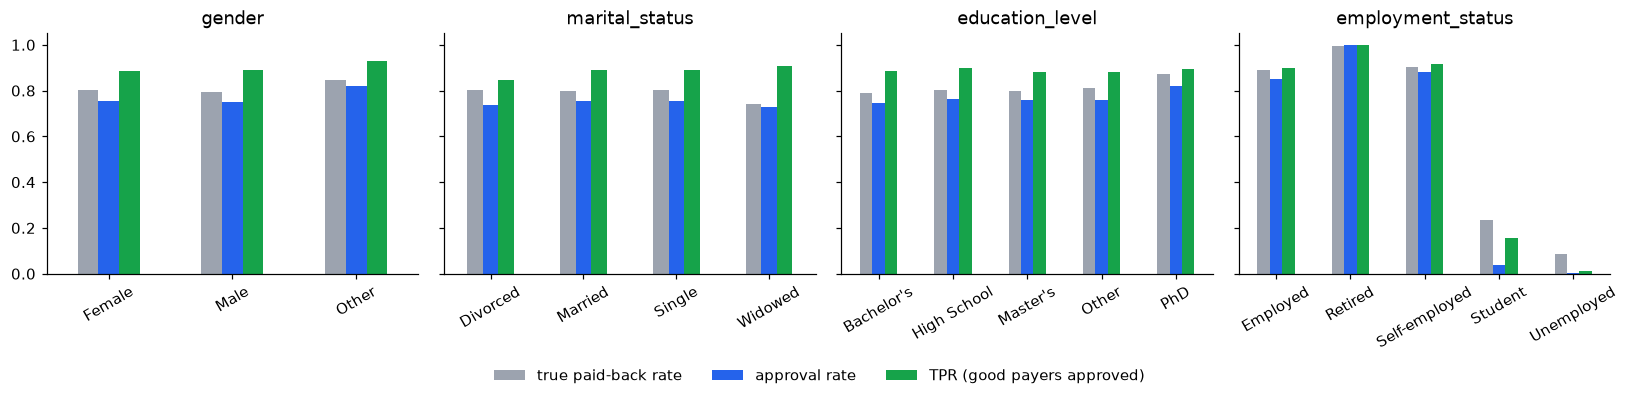

In [20]:
rep = fairness_report(y_test, p_test, test[SENSITIVE], THRESH)
display(fairness_summary_table(rep).round(3))
g = rep["gender"]["by_group"]
print(f"Headline Female vs Male (the 'Other' group has only {g.loc['Other', 'n']} rows): "
      f"approval gap = {g.loc['Female', 'approval_rate'] - g.loc['Male', 'approval_rate']:+.3f}, "
      f"TPR gap = {g.loc['Female', 'TPR'] - g.loc['Male', 'TPR']:+.3f}")
for col in SENSITIVE:
    display(rep[col]["by_group"].round(3))

fig, ax = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for a, col in zip(ax, SENSITIVE):
    rep[col]["by_group"][["base_rate", "approval_rate", "TPR"]].plot.bar(ax=a, rot=30, color=[C["grey"], C["main"], C["ok"]], legend=False, title=col)
    a.set_xlabel("")
fig.legend(["true paid-back rate", "approval rate", "TPR (good payers approved)"], loc="lower center", ncol=3, bbox_to_anchor=(0.5, -0.08), frameon=False)
savefig("11_fairness_by_group")

### 7.2 Step 1: formal fairness tests
Six definitions from the three families of Barocas, Hardt & Narayanan:
- **independence:** statistical parity, and conditional statistical parity within credit-score quintiles;
- **separation:** equal opportunity, predictive equality, equalized odds;
- **sufficiency:** the same score means the same repayment rate in every group.

H0 = "the model is fair" under each definition. The values in the table are **p-values**, and anything below 0.05 means fairness is rejected (chi-square tests, stratified for the conditional definitions).

In [21]:
tests = pd.DataFrame({col: fairness_tests(y_test, p_test, test[col], THRESH, test.credit_score) for col in SENSITIVE})
mfm = test.gender.isin(["Female", "Male"]).to_numpy()
tests.insert(1, "gender (F vs M)", fairness_tests(y_test[mfm], p_test[mfm], test.gender[mfm], THRESH, test.credit_score[mfm]))
display(tests.round(4).style.map(lambda v: "background-color: #fecaca" if v < 0.05 else "background-color: #dcfce7").format("{:.4f}"))

print("Conditional statistical parity: approval rate by EDUCATION within credit-score quintiles")
display(conditional_parity(p_test, test.education_level, test.credit_score, THRESH).round(3))
print("Where are the unemployed? (share of each education level)")
display(test.groupby("education_level").employment_status.value_counts(normalize=True).unstack().round(3)[["Unemployed", "Student", "Retired"]])

,gender,gender (F vs M),marital_status,education_level,employment_status
statistical parity,0.1869,0.5174,0.6121,0.0034,0.0000
conditional statistical parity,0.6601,0.7532,0.3809,0.0153,0.0000
equal opportunity,0.3084,0.4529,0.0060,0.2069,0.0000
predictive equality,0.5424,0.2688,0.0327,0.0064,0.0000
equalized odds,0.4664,0.4093,0.0017,0.0097,0.0000
sufficiency,0.3495,0.0293,0.1541,0.8893,0.0002


Conditional statistical parity: approval rate by EDUCATION within credit-score quintiles


group,Bachelor's,High School,Master's,Other,PhD
risk_bin,,,,,
"(466.999, 636.0]",0.573,0.605,0.616,0.644,0.757
"(636.0, 669.0]",0.674,0.690,0.708,0.671,0.818
"(669.0, 695.0]",0.793,0.782,0.767,0.777,0.803
"(695.0, 727.0]",0.806,0.836,0.821,0.785,0.797
"(727.0, 848.0]",0.883,0.899,0.891,0.922,0.889


Where are the unemployed? (share of each education level)


employment_status,Unemployed,Student,Retired
education_level,,,
Bachelor's,0.109,0.021,0.026
High School,0.102,0.020,0.028
Master's,0.100,0.020,0.025
Other,0.084,0.020,0.021
PhD,0.053,0.019,0.043


### 7.3 Can we *certify* fairness? Equivalence test (TOST)
With 20,000 rows, the classical test flags tiny gaps as "significant", and its non-rejection does not prove anything. Following the bioequivalence logic of the course (slides 263–277), we test:
- H0: |gap| ≥ δ (unfair) against H1: |gap| < δ (fair within δ);
- δ = **2 percentage points** of approval rate, fixed before looking at the results;
- rejecting H0 **certifies** that the gap is smaller than δ.

In [22]:
approved = p_test >= THRESH
pairs = [("gender", "Female", "Male"), ("marital_status", "Single", "Married"),
         ("marital_status", "Divorced", "Married"), ("marital_status", "Widowed", "Married"),
         ("education_level", "High School", "Bachelor's"), ("education_level", "PhD", "Bachelor's")]
tost = pd.DataFrame({f"{a}: {pr} vs {rf}": tost_parity(approved, test[a], pr, rf, delta=DELTA_TOST) for a, pr, rf in pairs}).T
tost["n protected"] = [int((test[a] == pr).sum()) for a, pr, rf in pairs]
display(tost[["gap (ref - protected)", "CI 90%", "p-value", "certified fair", "n protected"]])

,gap (ref - protected),CI 90%,p-value,certified fair,n protected
gender: Female vs Male,-0.003956,"(-0.01400877039628308, 0.00609641650785149)",0.004332,True,10155
marital_status: Single vs Married,0.000386,"(-0.009864833117832912, 0.010636743101999675)",0.000825,True,9757
marital_status: Divorced vs Married,0.016588,"(-0.010596354214525025, 0.04377329166803416)",0.418226,False,762
marital_status: Widowed vs Married,0.028161,"(-0.025913780811880678, 0.08223555243384595)",0.598032,False,187
education_level: High School vs Bachelor's,-0.017575,"(-0.02917389309907753, -0.005975740851861864)",0.365451,False,6085
education_level: PhD vs Bachelor's,-0.073554,"(-0.10717426587777237, -0.0399347316348315)",0.995602,False,374


### 7.4 Step 2: which variables drive the unfairness? Fairness PDP and candidate variables
Statistical parity on `education_level` is clearly rejected (p = 0.003). The FPDP sets a feature to the **same value for everyone**, re-predicts, and re-runs the fairness test. A feature is a **candidate** (a channel of unfairness) if some value brings the p-value above 5%.

This runs on 4,000 test applicants, where parity is already rejected (p = 0.010), because each FPDP point costs 4,000 TabPFN predictions.

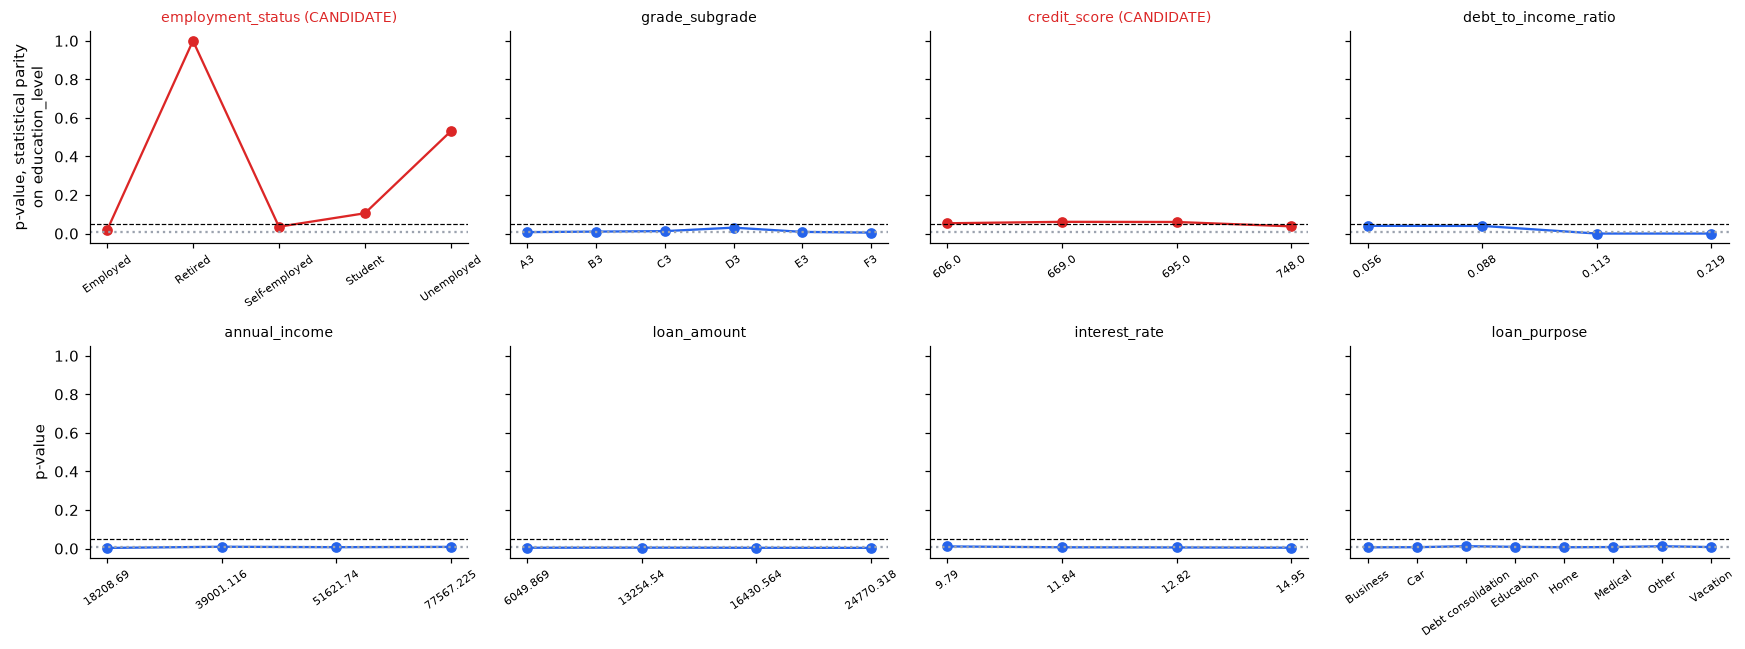

baseline p-value = 0.0099; candidate variables: ['employment_status', 'credit_score']
statistical parity on education: p = 0.0034 | conditional on employment status: p = 0.321
marital status, equal opportunity (good payers approved): p = 0.0060 | conditional on employment status: p = 0.0081


In [23]:
N_F = 4_000
Xf, yf, edu_f = X_test.iloc[:N_F], y_test[:N_F], test.education_level.to_numpy()[:N_F]
q = lambda c: np.quantile(X_test[c], [0.1, 0.4, 0.6, 0.9]).round(3)
grade_codes = [levels["grade_subgrade"].index(g) for g in ["A3", "B3", "C3", "D3", "E3", "F3"]]
FP_GRID = {"employment_status": range(len(levels["employment_status"])), "grade_subgrade": grade_codes,
           "credit_score": q("credit_score"), "debt_to_income_ratio": q("debt_to_income_ratio"),
           "annual_income": q("annual_income"), "loan_amount": q("loan_amount"), "interest_rate": q("interest_rate"),
           "loan_purpose": range(len(levels["loan_purpose"]))}
base_p = fairness_tests(yf, p_test[:N_F], edu_f, THRESH)["statistical parity"]
fp = {f: cache(f"fpdp_education_{f}", lambda f=f, gr=gr: fpdp(model.predict_proba, Xf, yf, edu_f, f, list(gr), THRESH))
      .fillna({"p-value": 1.0})   # everybody approved (or rejected) -> parity holds trivially
      for f, gr in FP_GRID.items()}

fig, axs = plt.subplots(2, 4, figsize=(16, 6), sharey=True)
cand = {}
for a, (f, r) in zip(axs.ravel(), fp.items()):
    labels = [levels[f][int(v)] if f in CAT_COLS else v for v in r.index]
    cand[f] = bool((r["p-value"] > 0.05).any())
    a.plot(range(len(r)), r["p-value"], "o-", color=C["neg"] if cand[f] else C["main"])
    a.axhline(0.05, ls="--", c="k", lw=.8); a.axhline(base_p, ls=":", c=C["grey"])
    a.set_xticks(range(len(r))); a.set_xticklabels(labels, rotation=35, fontsize=7)
    a.set_title(f + (" (CANDIDATE)" if cand[f] else ""), fontsize=9, color=C["neg"] if cand[f] else "k")
axs[0, 0].set_ylabel("p-value, statistical parity\non education_level"); axs[1, 0].set_ylabel("p-value")
savefig("12_fpdp_education")
print(f"baseline p-value = {base_p:.4f}; candidate variables: {[f for f, c in cand.items() if c]}")

# Confirmation on the full test set: is the education gap still there AMONG applicants with the same employment status?
from isaf_eval import _chi2
appr = (p_test >= THRESH).astype(int)
emp_t = test.employment_status.to_numpy()
print(f"statistical parity on education: p = {tests.loc['statistical parity', 'education_level']:.4f} | "
      f"conditional on employment status: p = {_chi2(appr, test.education_level.to_numpy(), emp_t)[2]:.3f}")
m1 = y_test == 1
print(f"marital status, equal opportunity (good payers approved): p = {tests.loc['equal opportunity', 'marital_status']:.4f} | "
      f"conditional on employment status: p = {_chi2(appr[m1], test.marital_status.to_numpy()[m1], emp_t[m1])[2]:.4f}")

**Reading:**
- **Education.** The gap disappears once we compare applicants with the same employment status. PhDs are approved more because only 5% of them are unemployed, against 10–11% for the other levels. The FPDP points to the same channel: `employment_status`, and to a lesser extent `credit_score`. This is a disparity **explained by a legitimate risk factor**, not a direct effect of education.
- **Marital status.** Divorced good payers are approved less often (TPR 84.5% vs 89%), and employment does not explain it. The model is also less accurate for divorced applicants (AUC 0.86 vs 0.92). The model never sees `marital_status`, so this gap comes through **proxies**. Adding the attribute back would not fix it either (7.5). It is a point to monitor, on a small group (762 test applicants).

### 7.5 Step 3: mitigation, and its cost
- **Panel B, without re-estimation:** fix a candidate variable to a single value for everyone, as in the FPDP. This gives the p-value and the AUC for each choice (4,000 applicants).
- **Panel A, with re-estimation:** refit TabPFN on other feature sets, evaluated on the full test set.

We compare the main model (no gender / marital status) with two alternatives:
- a **reference only** model that *does* use them. It is not allowed, but it measures what the legal constraint costs;
- a model that also drops `employment_status`, the main candidate variable.

In [24]:
print(f"Panel B: mitigation without re-estimation (AUC of the unmitigated model on these rows: {roc_auc_score(yf, p_test[:N_F]):.4f})")
if any(cand.values()):
    display(pd.concat({f: fp[f].rename(index=lambda v, f=f: levels[f][int(v)] if f in CAT_COLS else v) for f, c in cand.items() if c}).round(4))

variants = {"with gender & marital (reference only: NOT allowed)": FEATURES,
            "main model (no gender / marital)": MODEL_FEATURES,
            "main model without employment_status": [c for c in MODEL_FEATURES if c != "employment_status"]}

def fit_variant(feats):
    m = TabPFNModel(features=feats, n_estimators=N_ESTIMATORS).fit(encode(context, levels), y_ctx)
    out = m.predict_proba(encode(valid, levels)), m.predict_proba(encode(test, levels))
    del m; free_mem()
    return out

rows, variant_preds = [], {}
for name, feats in variants.items():
    pv, pt = (p_val, p_test) if name == "main model (no gender / marital)" else cache("variant_" + "_".join(sorted(set(FEATURES) - set(feats))), lambda f=feats: fit_variant(f))
    variant_preds[name] = (pv, pt)
    t = best_threshold(y_val, pv, valid.loan_amount, valid.interest_rate)
    ft = {c: fairness_tests(y_test, pt, test[c], t, test.credit_score) for c in SENSITIVE}
    rows.append({"variant": name, "AUC": roc_auc_score(y_test, pt),
                 "profit (M€)": economic_metrics(y_test, pt, test.loan_amount, test.interest_rate, t)["profit"] / 1e6,
                 "SP p-value education": ft["education_level"]["statistical parity"],
                 "EOdds p-value marital": ft["marital_status"]["equalized odds"],
                 "SP p-value gender": ft["gender"]["statistical parity"],
                 "TOST F vs M certified": tost_parity(pt >= t, test.gender, "Female", "Male", DELTA_TOST)["certified fair"]})
unaware = pd.DataFrame(rows).set_index("variant")
print("Panel A: mitigation with re-estimation (full test set)")
display(unaware.round(4))

Panel B: mitigation without re-estimation (AUC of the unmitigated model on these rows: 0.9127)


p-value     AUC
employment_status Employed        0.0164  0.7925
                  Retired         1.0000  0.7801
                  Self-employed   0.0355  0.7920
                  Student         0.1053  0.7894
                  Unemployed      0.5311  0.7860
credit_score      606.0           0.0534  0.8906
                  669.0           0.0608  0.8946
                  695.0           0.0600  0.8945
                  748.0           0.0374  0.8968

Panel A: mitigation with re-estimation (full test set)


,AUC,profit (M€),SP p-value education,EOdds p-value marital,SP p-value gender,TOST F vs M certified
variant,,,,,,
with gender & marital (reference only: NOT allowed),0.9149,15.9588,0.0005,0.0022,0.1338,True
main model (no gender / marital),0.9149,16.0244,0.0034,0.0017,0.1869,True
main model without employment_status,0.7969,8.7615,0.0000,0.1332,0.3035,True


## 8. A robust TabPFN for production

The main model already excludes gender and marital status. The diagnostics give three more fixes, all cheap:

| Problem found | Fix |
|---|---|
| The fingerprint hash makes predictions react to a one-cent change (6.2) | **switch the fingerprint off** |
| 3.8% of decisions depend on *which* 10k context rows are drawn (6) | **context bagging:** average 5 TabPFN models, each with a different 10k context. This uses 50k training rows instead of 10k, and averages away the context lottery |
| The threshold must match the new score | re-choose it on validation |

We measure the stability of the bagged model the same way as in section 6: two **independent** bags (A and B, 10 different context sets in total) are compared on the same 2,000 applicants.

In [25]:
K_BAG = 5
FEATS_ROBUST = MODEL_FEATURES

def robust_member(k, rows):
    ctx_k = stratified_subsample(train_pool, N_CONTEXT, 1_000 + k)
    m = TabPFNModel(features=FEATS_ROBUST, n_estimators=N_ESTIMATORS, seed=1_000 + k, fingerprint=False).fit(encode(ctx_k, levels), ctx_k[TARGET])
    out = {name: m.predict_proba(X) for name, X in rows.items()}
    del m; free_mem()
    return out

bagA = [cache(f"robust_A_{k}", lambda k=k: robust_member(k, {"valid": X_val, "test": X_test, "noise1": add_noise(Xs, NUM_COLS, 0.01)})) for k in range(K_BAG)]
bagB = [cache(f"robust_B_{k}", lambda k=k: robust_member(K_BAG + k, {"stab": Xs})) for k in range(K_BAG)]
pr_val, pr_test = np.mean([b["valid"] for b in bagA], axis=0), np.mean([b["test"] for b in bagA], axis=0)
THRESH_R = best_threshold(y_val, pr_val, valid.loan_amount, valid.interest_rate)

stats_r = statistical_metrics(y_test, pr_test)
econ_r = economic_metrics(y_test, pr_test, test.loan_amount, test.interest_rate, THRESH_R)
ci_r = {"AUC": bootstrap_ci(lambda i: roc_auc_score(y_test[i], pr_test[i]), n),
        "profit": bootstrap_ci(lambda i: loan_profit(y_test[i], pr_test[i], la[i], ir[i], THRESH_R), n)}
# paired bootstrap of the AUC difference robust - baseline
ci_diff = bootstrap_ci(lambda i: roc_auc_score(y_test[i], pr_test[i]) - roc_auc_score(y_test[i], p_test[i]), n)

pA, pB = pr_test[:N_STAB], np.mean([b["stab"] for b in bagB], axis=0)
single = np.array([b["test"][:N_STAB] for b in bagA])
stab_r = {"single member vs single member": {**prediction_stability(single, THRESH_R), "material flips": material_flips(single, THRESH_R)},
          "bag A vs bag B": {**prediction_stability(np.array([pA, pB]), THRESH_R), "material flips": material_flips([pA, pB], THRESH_R)},
          "noise 1% (bagged)": prediction_stability(np.array([pA, np.mean([b["noise1"] for b in bagA], axis=0)]), THRESH_R)}
display(pd.DataFrame(stab_r).T.round(4))

,mean_abs_prob_change,decision_flip_rate,mean_per_row_std,material flips
single member vs single member,0.0242,0.0387,0.0180,0.0108
bag A vs bag B,0.0112,0.0145,0.0056,0.0022
noise 1% (bagged),0.0143,0.0215,0.0072,NaN


In [26]:
tests_r = pd.DataFrame({col: fairness_tests(y_test, pr_test, test[col], THRESH_R, test.credit_score) for col in SENSITIVE})
tost_r = tost_parity(pr_test >= THRESH_R, test.gender, "Female", "Male", DELTA_TOST)
cmp = pd.DataFrame({
    "main TabPFN": {"features": len(MODEL_FEATURES), "context rows used": N_CONTEXT, "threshold": THRESH,
                        "AUC": stats["AUC"], "AUC 95% CI": ci["AUC"], "Brier": stats["Brier"],
                        "profit (M€)": econ["profit"] / 1e6, "profit 95% CI (M€)": tuple(np.round(np.array(ci["profit"]) / 1e6, 2)),
                        "EV-rule profit (M€)": econ["profit_expected_value_rule"] / 1e6, "approval rate": econ["approval_rate"],
                        "flip rate: context lottery": stab.loc["context resampling", "decision_flip_rate"],
                        "flip rate: 1% noise": stab.loc["noise 1%", "decision_flip_rate"],
                        "SP p-value gender": tests.loc["statistical parity", "gender"],
                        "TOST F vs M certified (δ=2pp)": tost.iloc[0]["certified fair"],
                        "batch inference (ms / applicant)": latency_ms},
    "robust TabPFN": {"features": len(FEATS_ROBUST), "context rows used": K_BAG * N_CONTEXT, "threshold": THRESH_R,
                      "AUC": stats_r["AUC"], "AUC 95% CI": ci_r["AUC"], "Brier": stats_r["Brier"],
                      "profit (M€)": econ_r["profit"] / 1e6, "profit 95% CI (M€)": tuple(np.round(np.array(ci_r["profit"]) / 1e6, 2)),
                      "EV-rule profit (M€)": econ_r["profit_expected_value_rule"] / 1e6, "approval rate": econ_r["approval_rate"],
                      "flip rate: context lottery": stab_r["bag A vs bag B"]["decision_flip_rate"],
                      "flip rate: 1% noise": stab_r["noise 1% (bagged)"]["decision_flip_rate"],
                      "SP p-value gender": tests_r.loc["statistical parity", "gender"],
                      "TOST F vs M certified (δ=2pp)": tost_r["certified fair"],
                      "batch inference (ms / applicant)": latency_ms * K_BAG}})
display(cmp.map(lambda v: f"{v:.4f}" if isinstance(v, float) else (tuple(round(x, 4) for x in v) if isinstance(v, tuple) else v)))
print(f"AUC difference robust − main: {stats_r['AUC'] - stats['AUC']:+.4f}, paired-bootstrap 95% CI [{ci_diff[0]:+.4f}, {ci_diff[1]:+.4f}]")
print("Formal fairness tests of the robust model (p-values):"); display(tests_r.round(4))

,main TabPFN,robust TabPFN
features,9,9
context rows used,10000,50000
threshold,0.8000,0.8100
AUC,0.9149,0.9159
AUC 95% CI,"(0.9102, 0.9202)","(0.9113, 0.921)"
Brier,0.0742,0.0737
profit (M€),16.0244,16.0869
profit 95% CI (M€),"(15.3, 16.8)","(15.35, 16.8)"
EV-rule profit (M€),16.4664,16.4664
approval rate,0.7543,0.7447


AUC difference robust − main: +0.0010, paired-bootstrap 95% CI [-0.0002, +0.0023]
Formal fairness tests of the robust model (p-values):


,gender,marital_status,education_level,employment_status
statistical parity,0.1353,0.6179,0.0017,0.0000
conditional statistical parity,0.7778,0.2612,0.0072,0.0000
equal opportunity,0.3902,0.0131,0.7830,0.0000
predictive equality,0.2189,0.0081,0.0014,0.0000
equalized odds,0.2956,0.0010,0.0126,0.0000
sufficiency,0.4683,0.0594,0.7243,0.0003


**Reading:**
- **Stability.** Context bagging **cuts the context lottery by more than half**: 1.45% of decisions differ between two independent bags, against 3.8% between two single models. Clear-cut flips (score more than 0.05 from the threshold) fall from 2.0% to 0.2%. Noise sensitivity drops from 3.9% to 2.2%.
- **Performance.** Unchanged: AUC +0.001, and the 95% confidence interval of the difference contains 0. Profit is €16.1M against €16.0M.
- **Fairness.** Gender stays certified fair. The education and marital-status findings of section 7 are unchanged, because they come from proxies and not from the prohibited attributes.
- **Cost.** 5× the inference time (about 0.3 s per applicant on a laptop GPU). This is acceptable for a web app, but not for scoring millions of files in batch.

## 9. Export (for the comparison slide and the web app)

In [27]:
pd.DataFrame({"id": test.id, "y": y_test, "p_tabpfn": p_test, "p_tabpfn_robust": pr_test}).to_csv(OUT / "preds_tabpfn.csv", index=False)

summary = {"model": "TabPFN", "reproducibility": repro, "n_context": N_CONTEXT, "n_estimators": N_ESTIMATORS,
           "latency_ms_per_applicant": latency_ms, "threshold": THRESH,
           "statistical": {**stats, "AUC_CI95": ci["AUC"]}, "economic": {**econ, "profit_CI95": ci["profit"], "profit_grade_rule_status_quo": profit_grade},
           "interpretability": {"permutation_importance": imp.sort_values(ascending=False).to_dict(),
                                "mean_abs_shap": shap_imp.sort_values(ascending=False).to_dict(),
                                "xper": xp.to_dict(), "surrogate_fidelity_R2": fidelity,
                                "shap_vs_lime_agreement": agree},
           "stability": {**stab.to_dict(orient="index"), "importance_spearman": IMP_SPEARMAN, "importance_distance": IMP_DIST,
                         "auc_by_context_size": dict(zip(map(str, ns), aucs))},
           "fairness": {"summary": fairness_summary_table(rep).to_dict(orient="index"), "tests_pvalues": tests.to_dict(),
                        "tost": tost.drop(columns="CI 90%").to_dict(orient="index"), "fpdp_candidates": [f for f, c in cand.items() if c],
                        "mitigation": unaware.to_dict(orient="index")},
           "robust_model": {"features": FEATS_ROBUST, "n_contexts": K_BAG, "fingerprint": False, "threshold": THRESH_R,
                            "statistical": {**stats_r, "AUC_CI95": ci_r["AUC"]}, "economic": {**econ_r, "profit_CI95": ci_r["profit"]},
                            "stability": stab_r, "fairness_tests_pvalues": tests_r.to_dict()}}
(OUT / "summary_tabpfn.json").write_text(json.dumps(summary, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)))

# Web app: the ROBUST model (its 5 context sets + config); ~0.3 s per applicant on GPU
save_production_model(OUT / "model", [stratified_subsample(train_pool, N_CONTEXT, 1_000 + k) for k in range(K_BAG)],
                      levels, THRESH_R, FEATS_ROBUST, N_ESTIMATORS, fingerprint=False, seeds=[1_000 + k for k in range(K_BAG)],
                      extra={"test_auc": stats_r["AUC"], "lgd": LGD})
print("saved:", sorted(str(p.relative_to(OUT)) for p in OUT.rglob("*") if p.is_file() and "cache" not in p.parts))

saved: ['figures/01_data_drivers.png', 'figures/02_statistical_performance.png', 'figures/03_profit_curve.png', 'figures/04_permutation_importance.png', 'figures/05_shap_global.png', 'figures/06_local_explanations_shap_lime.png', 'figures/07_pdp_ice.png', 'figures/08_global_surrogate.png', 'figures/09_xper.png', 'figures/10_stability.png', 'figures/11_fairness_by_group.png', 'figures/12_fpdp_education.png', 'figures/13_three_features.png', 'model/tabpfn_config.json', 'model/tabpfn_context_0.csv.gz', 'model/tabpfn_context_1.csv.gz', 'model/tabpfn_context_2.csv.gz', 'model/tabpfn_context_3.csv.gz', 'model/tabpfn_context_4.csv.gz', 'preds_tabpfn.csv', 'summary_tabpfn.json']


**Web-app latency, measured.** TabPFN re-processes its whole context at every call. For a single applicant, the batch figure above is therefore misleading. The production loader switches on TabPFN's context cache (`fit_mode="fit_with_cache"`), and we check that the decisions are unchanged.

In [28]:
def production_check():
    t0 = time.time(); prod = load_production_model(OUT / "model"); t_load = time.time() - t0
    t0 = time.time()
    for i in range(5): prod.decide(test.iloc[[i]])
    t_one = (time.time() - t0) / 5
    p_prod = prod.predict_proba(test.iloc[:500])
    return {"startup: build + cache 5 contexts (s)": t_load, "one applicant (s)": t_one,
            "max |Δp| vs notebook (500 rows)": float(np.abs(p_prod - pr_test[:500]).max()),
            "decision flips vs notebook (500 rows)": int(np.sum((p_prod >= THRESH_R) != (pr_test[:500] >= THRESH_R)))}
display(pd.Series(cache("production_check", production_check)).round(4).to_frame("robust TabPFN, web app"))

,"robust TabPFN, web app"
startup: build + cache 5 contexts (s),56.8898
one applicant (s),1.1333
max |Δp| vs notebook (500 rows),0.0023
decision flips vs notebook (500 rows),0.0000


## 10. Takeaways for the deck

Numbers: 20,000-row test set (= `data/test_eval_20k.csv`), threshold chosen on validation, LGD = 70%. 95% CIs by bootstrap. The model uses **9 inputs: no gender, no marital status** (legally prohibited, used only for the fairness audit). "Robust" = the section 8 model.

| Dimension | TabPFN result | What to say |
|---|---|---|
| **Statistical perf.** | AUC **0.915** [0.910, 0.920], Gini 0.83, Brier 0.074, **ECE 0.005** (almost perfectly calibrated) | Reached with **10k context rows, i.e. 2% of the data**, with no training and no tuning. The legal constraint costs **nothing**: the same model *with* gender and marital status has the same AUC (0.915) and a lower profit |
| **Economic perf.** | Profit **€16.0M** [15.3, 16.8] on 20k loans, vs **−€12.9M** approving everyone and **€2.1M** for the status-quo grade rule. 69% of the oracle profit | The loan-specific expected-value rule (no tuning) earns **€16.5M**, more than the tuned threshold: calibration pays. XPER on profit: employment earns **+€793k** and DTI **+€466k** per 1,000 loans; the other features ≈ €0 |
| **Interpretability** | Drivers: employment, DTI, credit score. **Permutation importance, SHAP, surrogate and XPER all agree** on the top 3 (Spearman 0.84–0.98). Depth-3 surrogate tree fidelity **R² = 0.92**. SHAP vs LIME on individual applicants: same top 3, but **LIME's local fidelity is low (R² 0.09–0.18)** | Explanations are consistent because the signal is concentrated in 3 features (section 11). They remain **post-hoc approximations**: slow (SHAP on 40 applicants ≈ 17 min on GPU), and LIME's reasons look convincing while its surrogate fits poorly. Reason code example: *rejected because DTI = 0.235* |
| **Stability** | Context lottery: **3.8%** of decisions flip between two 10k contexts (0.9% from the seed alone). **1% input noise flips 3.9%**, almost all through DTI (GBM 1.5%, LR 0.15%). Explanations stable (Spearman 0.79, distance ‖φ1−φ2‖ = 8% of ‖φ‖). CPU vs GPU: tiny differences, 0 flips | The flexible models learn the **stepped DTI pattern** of the synthetic data. TabPFN's row-hash "fingerprint" makes a **one-cent change** flip decisions, and switching it off costs nothing |
| **Fairness** | **Gender:** fair under all 6 definitions, and the TOST **certifies** the gap is < 2 pp. **Education:** statistical parity rejected (PhD 82% vs Bachelor 75% approved), but **explained by employment** (p = 0.32 conditional on it), which is confirmed by the FPDP (candidates: employment, credit score). **Marital:** separation rejected, divorced good payers approved 84.5% vs 89%, *not* explained by employment, and present although the model never sees marital status (proxies) | Dropping employment would fix the marital gap, but AUC falls to 0.80 and profit by 45%: the fairness/performance trade-off is brutal. Education and marital gaps have to be discussed with the client, not hidden |
| **Robust TabPFN** | Fingerprint off + 5-context bagging: AUC 0.916, profit €16.1M, **context flips 3.8% → 1.45%** (clear-cut 2.0% → 0.2%), noise flips 3.9% → 2.2% | Robustness gained for free on performance, at 5× the inference cost |

**Recommendation angle (for the comparison with LR / XGB):** TabPFN is an excellent *out-of-the-box* model: top-tier AUC with 2% of the data, near-perfect calibration (which is what the expected-value decision rule needs), and highly profitable, all without the prohibited attributes. Our diagnostics also made it measurably more stable. For a lender's *production* engine, four points remain:
- **inference cost:** 55 ms per applicant in batch. A single web-app applicant takes about 1 s after about 1 min of context caching at startup (robust model, laptop GPU), where a GBM or LR scores in microseconds;
- **a context bounded by compute:** 50k rows at most here, out of the 470k available;
- **post-hoc explanations only:** they are consistent on this data, but slow and approximate, which clashes with GDPR art. 22 and the EU AI Act, since credit scoring is high-risk;
- **residual instability:** 1.5% of decisions still depend on which context sets are drawn.

Suggested positioning: a **challenger model** that audits and benchmarks the production model, deployed only if it beats XGB on profit by more than the confidence interval (±€0.8M here).

## 11. Open question (Ethan): how can TabPFN score so well with only three features that matter?

> *"As you can see, the model is dominated by three features despite our results. And `employment_status` is text (employed, self-employed, retired), so how do we get such good results with TabPFN? Should we categorise it into 3 binarised features?"*

We answer with the data rather than intuition, in three steps:
1. **Where the defaults are.** `employment_status` actually has **5** values, and the two that matter are *Student* and *Unemployed*.
2. **How much each feature adds.** TabPFN with 1, 2, 3 and all 9 input features, on the same context and the same 2,000 test applicants. A logistic regression on the full test set serves as a reference.
3. **Does the encoding of the text variable matter?** Categorical codes (current), one-hot (5 binaries), 3 risk binaries (Unemployed / Student / Retired, with Employed + Self-employed as baseline), and the code used as a plain number.

In [29]:
# 1. Where are the defaults?
emp_tab = test.groupby("employment_status")[TARGET].agg(n="count", paid_back_rate="mean")
emp_tab["share of applicants"] = emp_tab.n / len(test)
emp_tab["share of all defaults"] = (1 - test[TARGET]).groupby(test.employment_status).sum() / (1 - test[TARGET]).sum()
display(emp_tab.round(3))
rate = train_pool.groupby("employment_status")[TARGET].mean()
print(f"AUC of employment_status ALONE (score = repayment rate of the group): {roc_auc_score(y_test, test.employment_status.map(rate)):.3f}")
for g_ in ["Employed", "Self-employed"]:
    m_ = (test.employment_status == g_).to_numpy()
    print(f"TabPFN AUC *within* {g_}: {roc_auc_score(y_test[m_], p_test[m_]):.3f}  <- here the ranking comes from DTI and credit score")

,n,paid_back_rate,share of applicants,share of all defaults
employment_status,,,,
Employed,15226,0.892,0.761,0.410
Retired,534,0.996,0.027,0.000
Self-employed,1770,0.903,0.088,0.043
Student,408,0.235,0.020,0.078
Unemployed,2062,0.084,0.103,0.469


AUC of employment_status ALONE (score = repayment rate of the group): 0.776
TabPFN AUC *within* Employed: 0.822  <- here the ranking comes from DTI and credit score
TabPFN AUC *within* Self-employed: 0.809  <- here the ranking comes from DTI and credit score


,"TabPFN AUC (2,000 test rows)","LR AUC (20,000 test rows)",n features
employment only,0.7856,0.7755,1
+ debt_to_income_ratio,0.8890,0.8759,2
+ credit_score (the 3 drivers),0.9199,0.9060,3
all 9 features (current model),0.9213,0.9066,9
encoding: one-hot (5 binaries),0.9207,0.9066,13
encoding: 3 risk binaries,0.9210,0.9066,11
encoding: code as a plain number,0.9204,0.8881,9


decisions that change vs the current encoding: {'encoding: one-hot (5 binaries)': '0.9%', 'encoding: 3 risk binaries': '0.8%', 'encoding: code as a plain number': '1.0%'}


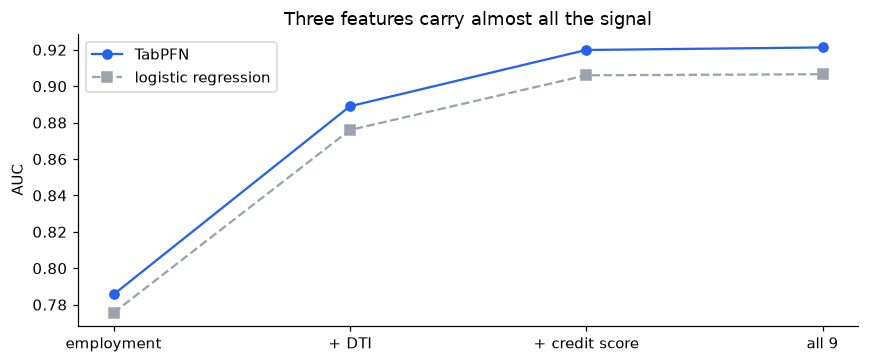

In [30]:
# 2. How much does each feature add?  3. Does the encoding matter?
def emp_variants(X):
    X = X.copy(); e = X.employment_status.astype(int)
    for k, name in enumerate(levels["employment_status"]):
        X[f"emp_is_{name}"] = (e == k).astype(float)
    X["emp_code_as_number"] = e.astype(float)   # NOT declared categorical -> treated as an ordered number
    return X
Xc_v, Xs_v = emp_variants(X_ctx), emp_variants(Xs)
others = [c for c in MODEL_FEATURES if c != "employment_status"]
onehot = [f"emp_is_{n_}" for n_ in levels["employment_status"]]
three = ["emp_is_Unemployed", "emp_is_Student", "emp_is_Retired"]
setups = {
    "employment only":                       ["employment_status"],
    "+ debt_to_income_ratio":                ["employment_status", "debt_to_income_ratio"],
    "+ credit_score (the 3 drivers)":        ["employment_status", "debt_to_income_ratio", "credit_score"],
    "all 9 features (current model)":        MODEL_FEATURES,
    "encoding: one-hot (5 binaries)":        others + onehot,
    "encoding: 3 risk binaries":             others + three,
    "encoding: code as a plain number":      others + ["emp_code_as_number"],
}
def q_fit(feats):
    m = TabPFNModel(features=feats, n_estimators=N_ESTIMATORS).fit(Xc_v, y_ctx)
    p_ = m.predict_proba(Xs_v); del m; free_mem(); return p_
q_pred = {k: (p_test[:N_STAB] if k == "all 9 features (current model)" else cache("q_" + k, lambda f=f: q_fit(f)))
          for k, f in setups.items()}

# reference: logistic regression (one-hot) on the same feature sets, full train pool, full test set
Xtr_v, Xte_v = emp_variants(encode(train_pool, levels)[MODEL_FEATURES]), emp_variants(X_test)
def lr_auc(feats):
    num = [c for c in feats if c in NUM_COLS or c.startswith("emp_")]
    cat = [c for c in feats if c in CAT_COLS]
    pipe = make_pipeline(ColumnTransformer([("c", OneHotEncoder(handle_unknown="ignore"), cat), ("n", StandardScaler(), num)]),
                         LogisticRegression(max_iter=2000)).fit(Xtr_v[feats], train_pool[TARGET])
    return roc_auc_score(y_test, pipe.predict_proba(Xte_v[feats])[:, 1])
q_tab = pd.DataFrame({"TabPFN AUC (2,000 test rows)": {k: roc_auc_score(ys, p_) for k, p_ in q_pred.items()},
                      "LR AUC (20,000 test rows)": {k: lr_auc(f) for k, f in setups.items()}})
q_tab["n features"] = [len(f) for f in setups.values()]
display(q_tab.round(4))
flip_enc = {k: float(np.mean((q_pred[k] >= THRESH) != (p_test[:N_STAB] >= THRESH))) for k in setups if k.startswith("encoding")}
print("decisions that change vs the current encoding:", {k: f"{v:.1%}" for k, v in flip_enc.items()})

fig, ax = plt.subplots(figsize=(8, 3.4))
steps = list(setups)[:4]
ax.plot(range(4), q_tab.loc[steps, "TabPFN AUC (2,000 test rows)"], "o-", color=C["main"], label="TabPFN")
ax.plot(range(4), q_tab.loc[steps, "LR AUC (20,000 test rows)"], "s--", color=C["grey"], label="logistic regression")
ax.set_xticks(range(4)); ax.set_xticklabels(["employment", "+ DTI", "+ credit score", "all 9"]); ax.set_ylabel("AUC")
ax.set_title("Three features carry almost all the signal"); ax.legend()
savefig("13_three_features")

**Answer.**

**1. Why so good with three features.** The data (synthetic) is built that way:
- *Unemployed* and *Student* are **12% of applicants but more than half of all defaults**, and their repayment rates are 8% and 24% against about 90% for everyone else. `employment_status` alone already gives an AUC of about 0.78.
- Within the employed, the ranking comes from DTI and credit score, which add the rest. The other 6 input features are close to noise (XPER: ≈ 0 € of profit).
- Measured: employment alone 0.786 → + DTI 0.889 → + credit score **0.920**, against 0.921 with all 9 input features.
- So the high AUC is **not** TabPFN "inventing" signal. The signal is concentrated, and every good model finds it: the logistic regression goes 0.776 → 0.876 → 0.906 with the same three features.
- TabPFN's edge over LR (+0.013 AUC with the same 3 features) comes from the **non-linearities**: the stepped DTI and the employment × DTI interactions.

**2. "It's text": how does TabPFN read it?** The text is never given as text. It is converted to integer codes, and we **declare** the column as categorical (`categorical_features_indices`). TabPFN then handles it internally as a category, not as an ordered number.

**3. Should we binarise into 3 features?** For TabPFN, the table shows it **changes almost nothing**:
- one-hot, 3 risk binaries and plain codes all give an AUC between 0.920 and 0.921;
- 0.8–1.0% of decisions change, which is the order of the seed noise (0.9%, section 6);
- the model works with any reasonable encoding.
- Merging *Retired* with *Employed/Self-employed* would not lose much either (99.6% vs 89–90% repayment, but only 2.7% of applicants).

**When binarising *is* worth it:**
- **for interpretability and fairness.** Three explicit flags (`is_unemployed`, `is_student`, `is_retired`) make the explanation readable ("rejected mainly because unemployed"), and they make the key business question explicit: *is refusing students legitimate?*;
- **for the white-box model.** For LR, one-hot / binaries are *required*. Treating the code as a number imposes a fake order Employed < Retired < Self-employed < Student < Unemployed, and the AUC drops from 0.907 to **0.888**. That problem does not exist for TabPFN once the column is declared categorical.

**Takeaway for the deck.** This is a *data* story more than a *model* story. Three variables drive the decision, and one of them (employment) splits the population into "has an income" and "does not". It is also the reason why **stability depends on DTI** (6.2) and **fairness depends on employment** (7.4). A lender should validate this concentration of risk explicitly, since it means a small drift in the employment mix would move the whole portfolio.